# The circuit behind Qwen3's algorithm choice (K3): `method.py` as a runnable demo

**Research question of the run:** how is an LLM's choice of *which* solution to write made inside the model, and can we
push it to a different solution? This artifact looks at one place where the choice is made. When Qwen3-8B (bf16,
thinking off) writes a program, the algorithm is often fixed by a **single decision token**:

* **C1 (primary): minimum spanning tree weight (unit B3).** After B3's 61-token canonical opening
  (`...graph[v].append((u, w))\n\n    #`), the next token is ` Kr` (Kruskal) or ` Prim`.
  Metric `m = z(' Kr') - z(' Prim')` at the decision position (DEC).
* **C2a (replication): connected components (T10).** After `def solve(n, edges):\n    def`, the next token is
  ` find` (union-find) or ` dfs`. Metric `m = z(' find') - z(' dfs')`.

`method.py` finds the components (attention heads and MLPs at four position classes COND / SPEC / OPEN / DEC) that
compute this logit difference:

1. **Contrasts.** Pairs of a clean (default-leaning) and a corrupt (minority-leaning) prompt: C1-nat noun variants,
   C1-forced paraphrases ("Implement Prim's algorithm ...") against padding twins, and the C2a state exchange.
2. **Circuit.** An attribution-patching (AtP) screen of every node, then exact noising and denoising of the top nodes,
   path patching among the top 15, and faithfulness curves.
3. **Commit #1.** Frozen top-10, plus write-norm-matched random components (the null).
4. **Validation.** ABLATE and STEER each top node in the real model against matched random components, with an exact
   sign-flip test and Holm correction.
5. **Steering.** Steer the top-5 at the decision position, then look at generation and the decision-token probability
   (dose response).

**What this notebook runs.** The same code, split into cells. Two things change. First, the model is **Qwen3-0.6B**,
which has the same tokenizer, so the original prompt token ids are valid. Second, every sample size is set to the
small values in the config cell, so the demo runs on a CPU in a few minutes. Set the config values back to the
originals (in comments) for the full run, which needs a GPU. The original run's stages took about 2.4 GPU-hours on one
NVIDIA L4 with Qwen3-8B.

Not run here: generation of full programs and their hidden-test labelling, which needs the iteration-6 CRN sampler and
the labeller. The Qwen3-8B results of those stages are loaded from `mini_demo_data.json` and plotted at the end, next
to this run's numbers.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install
_pip('loguru==0.7.3')

# torch, transformers, tokenizers, huggingface_hub, numpy, scipy, matplotlib — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('torch==2.9.0', '--index-url', 'https://download.pytorch.org/whl/cpu')
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'transformers==5.0.0', 'tokenizers==0.22.2',
         'huggingface_hub==1.4.0')

In [2]:
from __future__ import annotations

# --- method.py's imports
import argparse
import gc
import json
import sys
import time
from pathlib import Path
from typing import Any

import numpy as np
import torch
from loguru import logger

# --- imports of the src/ modules inlined below (k3cfg, k3engine, k3prompts, k3circuit, k3stats)
import contextlib
import hashlib
import math
import os
import resource
from datetime import datetime, timezone
from typing import Callable, Iterable, Iterator

from scipy.stats import binom, norm

# --- notebook additions
import shutil
from types import SimpleNamespace

import matplotlib.pyplot as plt
import transformers

transformers.logging.disable_progress_bar()
print("torch", torch.__version__, "| transformers", transformers.__version__, "| numpy", np.__version__)

torch 2.9.0+cpu | transformers 5.0.0 | numpy 2.0.2


In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-8/experiment-41/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["metadata"]["method_name"], "|", data["metadata"]["model"])
print("summary sections:", list(data["metadata"]["summary"]))
print("inputs for the pipeline:", [k for k in data["metadata"]["demo_inputs"] if k != "source"])
print("dataset:", data["datasets"][0]["dataset"], "-", len(data["datasets"][0]["examples"]), "generation slots")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
K3 circuit discovery and validation for the algorithm-choice decision token | Qwen/Qwen3-8B@b968826d (bf16, thinking off)
summary sections: ['contrasts', 'circuits', 'validation', 'validation_sensitivity', 'generation', 'dose_sensitivity', 'motif', 'cross_contrast_overlap', 'stability', 'K3', 'gpu_tests', 'tests_cpu']
inputs for the pipeline: ['prompts7', 'forks_B3_opening', 'forks_T10', 'noun_bank']
dataset: B3_mst_weight_C1forced_generation - 60 generation slots


## Configuration

All tunable parameters of `method.py` / `src/k3cfg.py` are collected here. They are set to small values so the
notebook runs in minutes on a CPU. **Original values are in the comments**; set them back, with
`MODEL_ID = "Qwen/Qwen3-8B"` on a ≥ 20 GB GPU, to reproduce the full run. The pre-registered rules (seeds, the
`TE_MIN` pair filter, the dose of 2, the Holm and sign-flip tests) are unchanged.

In [5]:
# ---------------------------------------------------------------- model (the original: bf16 Qwen3-8B on one NVIDIA L4)
MODEL_ID = "Qwen/Qwen3-0.6B"                          # original: "Qwen/Qwen3-8B"
MODEL_REVISION = "c1899de289a04d12100db370d81485cdf75e47ca"  # original: "b968826d9c46dd6066d109eabc6255188de91218"
N_LAYERS, N_HEADS, HEAD_DIM, D_MODEL = 28, 16, 128, 1024  # original (Qwen3-8B): 36, 32, 128, 4096
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # original: "cuda" (hard-coded)
DTYPE = torch.bfloat16                                # original: bf16 (thinking off, sdpa attention)
FRESH_RUN = True                                      # delete the previous demo run directory first

# ---------------------------------------------------------------- contrasts
TEMPLATES = ("W1", "W2", "W3")                        # original: ("W1", "W2", "W3", "W4", "W5")
N_NOUNS_PER_TEMPLATE = 8                              # original: 24 neutral-noun variants per template (C1-nat)
PAIR_KS_A = (1, 2, 3)                                 # original: (1, 2, 3) k-th highest vs k-th lowest m (pair set A)
PAIR_KS_B = (4,)                                      # original: (4, 5, 6) disjoint pair set B (stability)
N_FORCED_PAIRS = 4                                    # original: 10 forced-Prim paraphrase pairs (C1-forced)
N_FORCED_HELDOUT = 2                                  # original: 5 held-out paraphrase pairs
TE_MIN = 0.2                                          # original: 0.2 (pairs with total effect <= 0.2 nats are dropped)

# ---------------------------------------------------------------- circuit (screen, exact patching, edges, faithfulness)
N_REL_PER_CLASS = 4                                   # original: 40 random nodes per class (AtP reliability check)
N_TOP_EXACT = 10                                      # original: 60 top-AtP nodes exact-noised and denoised
N_TOP_EXACT_F4 = 12                                   # original: 120 (F4: AtP-vs-exact Spearman < 0.6)
N_CAL = 6                                             # original: 20 random calibration nodes
IG_ALPHAS = (0.3, 0.7)                                # original: (0.1, 0.3, 0.5, 0.7, 0.9) IG-AtP interpolation points
N_EDGE = 6                                            # original: 15 (path patching among the top 15)
KS_FAITH = (1, 2, 5, 10)                              # original: (5, 10, 15, 30, 60)

# ---------------------------------------------------------------- validation and steering
N_VAL = 10                                            # original: 10 (every top-10 node is validated)
N_RAND = 10                                           # original: 50 matched random components per node
VAL_MAX_PROMPTS = None                                # original: None (every pair prompt + the held-out prompts)
STEER_DOSE = 2.0                                      # original: 2.0 (own + 2 x (opposite mean - own mean))
print(f"{MODEL_ID} on {DEVICE} ({DTYPE}); templates {TEMPLATES}; N_RAND {N_RAND}")

Qwen/Qwen3-0.6B on cpu (torch.bfloat16); templates ('W1', 'W2', 'W3'); N_RAND 10


## `src/k3cfg.py`: paths, fixed design constants, utilities

Node convention (from the module docstring): a node is `(kind 'head'|'mlp', layer, head (-1 for mlp), position
class)`. The head activation is the head's 128-d slice of the `o_proj` **input** (z), and the MLP activation is the
MLP output. Qwen3-8B has 36 × (32 + 1) × 4 = 4,752 nodes; Qwen3-0.6B has 28 × (16 + 1) × 4 = 1,904. Position classes:
COND = the condition sentence, SPEC = chat head + task spec + chat tail, OPEN = the teacher-forced opening, and
DEC = the position whose logits choose the decision token.

Sign convention: clean = default-leaning run (higher m) and corrupt = minority-leaning run, so TE = m_clean − m_corrupt > 0.
The noising effect of a node is m_clean − m_noised.

The run directory `k3_demo_run/` replaces the repository root: `results/`, `data/`, `cache/` and `predictions/` are
written there exactly as the original writes them.

In [6]:
ROOT = Path("k3_demo_run").resolve()   # original: the repository root (Path(__file__).resolve().parents[1])
if FRESH_RUN and ROOT.exists():
    shutil.rmtree(ROOT)
SRC = ROOT / "src"
INPUTS = ROOT / "inputs"
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
PRED_DIR = ROOT / "predictions"
CACHE_DIR = ROOT / "cache"
AUDIT_DIR = ROOT / "audit"
for _d in (DATA_DIR, RESULTS_DIR, FIG_DIR, LOG_DIR, PRED_DIR, CACHE_DIR, AUDIT_DIR):
    _d.mkdir(parents=True, exist_ok=True)

I6_SRC = INPUTS / "iter6_exp30" / "src"
E26 = INPUTS / "iter5_exp26"
E35 = INPUTS / "exp35"
E34 = INPUTS / "exp34"
E38 = INPUTS / "exp38"
I6_PROMPTS = INPUTS / "iter6_exp30" / "prompts" / "prompts6.jsonl"
NOUN_BANK = INPUTS / "dep_noun_bank.json"
COMMITS = ROOT / "commitments.log"

# ------------------------------------------------------------------------------------------------ model
# MODEL_ID, MODEL_REVISION, N_LAYERS, N_HEADS, HEAD_DIM, D_MODEL and the demo-scale design constants: see the
# config cell above
IM_END = 151645
ENDOFTEXT = 151643
TEMPLATE_TAIL = "<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"
PRECISION = "bf16"
CLASSES = ("COND", "SPEC", "OPEN", "DEC")
U_LEN = 1536

# ------------------------------------------------------------------------------------------------ design (commit #0)
SEED_HELDOUT = 8301
SEED_POOL = 8302
SEED_RAND5 = 8303
SEED_REL = 8304
SEED_CAL = 8305
EDGE_FRAC = 0.05
ATP_SPEARMAN_MIN = 0.6
GEN_SLOTS = tuple(range(6))
GEN_THRESH_PLUS = 6
GEN_PASS_RATIO = 0.8
MAX_NEW_GEN = 1024
GEN_BATCH = 15
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"
JUDGE_CAP_USD = 0.30
EXCLUDED_NOUNS = {"tree", "road", "roads", "city", "cities", "bridge", "network", "map", "heap", "graph", "path", "line",
                  "edge", "node", "link", "chain", "street", "key", "cost", "weight", "forest", "ship", "house", "set",
                  "union", "queue", "stack", "list", "number", "point", "table", "train", "plane", "circle", "ring",
                  "web", "net", "wire", "cable", "pipe", "rail", "track", "route", "way", "door", "gate", "wall"}

B3_TOK = {"a": " Kr", "b": " Prim"}          # C1 metric m = z(' Kr') - z(' Prim')
T10_TOK = {"a": " find", "b": " dfs", "b2": " bfs"}  # C2a m = z(' find') - z(' dfs')


# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def detect_cpus() -> int:
    try:
        q = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read_text())
        p = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read_text())
        if q > 0:
            return max(1, math.ceil(q / p))
    except (FileNotFoundError, ValueError):
        pass
    try:
        return len(os.sched_getaffinity(0))
    except (AttributeError, OSError):
        return os.cpu_count() or 1


def container_ram_gb() -> float | None:
    for p in ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory/memory.limit_in_bytes"):
        try:
            v = Path(p).read_text().strip()
            if v != "max" and int(v) < 1_000_000_000_000:
                return int(v) / 1e9
        except (FileNotFoundError, ValueError):
            pass
    return None


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (iteration-7 convention)."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def u_stream(*key: Any, n: int = U_LEN) -> np.ndarray:
    return np.random.Generator(np.random.PCG64(stable_seed(*key))).random(n)


def model_path(model_id: str = MODEL_ID, revision: str | None = MODEL_REVISION) -> str:
    cache = os.environ.get("HF_HUB_CACHE")
    if cache:
        snaps = Path(cache) / ("models--" + model_id.replace("/", "--")) / "snapshots"
        if revision and (snaps / revision).exists():
            return str(snaps / revision)
    return model_id


def _json_default(o: Any) -> Any:
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if isinstance(o, tuple):
        return list(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path, obj: Any) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=1, default=_json_default))
    tmp.replace(p)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping malformed line in {p.name}")
    return out


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with open(p, "a") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
        fh.flush()


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with open(tmp, "w") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
    tmp.replace(p)


def log_deviation(dev_id: str, text: str, severity: str = "minor") -> None:
    p = RESULTS_DIR / "deviations.json"
    cur = read_json(p) if p.exists() else []
    if any(d["id"] == dev_id for d in cur):
        return
    cur.append({"id": dev_id, "severity": severity, "text": text, "utc": utc_now()})
    write_json(p, cur)
    logger.warning(f"DEVIATION {dev_id}: {text}")


def stage_time(stage: str, seconds: float, **extra: Any) -> None:
    append_jsonl(RESULTS_DIR / "stage_timing.jsonl", [{"stage": stage, "seconds": round(seconds, 1), "utc": utc_now(),
                                                       **extra}])


setup_logging("method")
print("run directory:", ROOT.name)

run directory: k3_demo_run


### Inputs

`method.py` reads its prompts from read-only copies of earlier artifacts under `inputs/`:

* the iteration-7 twin prompts (`exp35/prompts/prompts7.jsonl`), with token ids and the condition/spec spans;
* the B3 canonical opening (`exp35/results/forks.json`) and the T10 fork (`exp34/results/forks.json`);
* the noun bank used for the C1-nat variants (`dep_noun_bank.json`).

These are bundled in `mini_demo_data.json`. The cell below writes them back into the same layout, so the prompt code
runs unchanged.

In [7]:
DI = data["metadata"]["demo_inputs"]
(E35 / "prompts").mkdir(parents=True, exist_ok=True)
write_jsonl(E35 / "prompts" / "prompts7.jsonl", DI["prompts7"])
write_json(E35 / "results" / "forks.json", {"B3": {"opening": DI["forks_B3_opening"]}})
write_json(E34 / "results" / "forks.json", {"tasks": {"T10": DI["forks_T10"]}})
write_json(NOUN_BANK, DI["noun_bank"])
print(len(DI["prompts7"]), "twin prompts;", "B3 opening:", repr(DI["forks_B3_opening"]["O_text"][-60:]))

10 twin prompts; B3 opening: 'aph[u].append((v, w))\n        graph[v].append((u, w))\n\n    #'


## `src/k3engine.py`: model loading, component edit hooks, cached forwards, AtP gradients

Edit sites:

* `'z'` is the input of block l's `o_proj`; a head edit touches its 128-d slice.
* `'mlp'` is the MLP output.
* `'resid'` is a decoder block's output, used only for the C2a state exchange.
* `'emb'` is the embedding output.

`margins_rows()` measures each edited row against an **unedited base row in the same batch chunk**, so bf16
batch-shape offsets cancel. The prompt prefix before the first edited position is prefilled once and reused (suffix
forward). `Metric` reads m in fp32 from the final-norm hidden state, because the bf16 `lm_head` output is quantised
to 0.125–0.25 nats.

*Notebook changes:* `"cuda"` became `DEVICE`, and `load_model` skips the CUDA memory calls on a CPU. The
generation-only functions (`e5`, `generate`, `sample_token`, which wrap the iteration-6 CRN sampler) are not
included because this demo does not generate programs.

In [8]:
_E5: dict[str, Any] = {}


# ================================================================================================ model
def load_model(vram_fraction: float = 0.96) -> tuple[Any, Any, dict[str, Any]]:
    from transformers import AutoModelForCausalLM, AutoTokenizer

    t0 = time.time()
    path = model_path(MODEL_ID, MODEL_REVISION)
    kw = {"revision": MODEL_REVISION} if path == MODEL_ID else {}
    tok = AutoTokenizer.from_pretrained(path, **kw)
    cuda = DEVICE == "cuda"                                 # notebook: CPU fallback (the original ran on one L4)
    free0, total = torch.cuda.mem_get_info(0) if cuda else (0, 0)
    model = AutoModelForCausalLM.from_pretrained(path, dtype=DTYPE, attn_implementation="sdpa", **kw).to(DEVICE)
    model.eval()
    model.requires_grad_(False)
    _MODEL["model"] = model
    gc.collect()
    torch.cuda.empty_cache()
    if cuda:
        torch.cuda.set_per_process_memory_fraction(vram_fraction, 0)
    free, total = torch.cuda.mem_get_info(0) if cuda else (0, 0)
    info = {"precision": str(DTYPE), "attn_implementation": "sdpa", "cpu_embedding": False,
            "free_vram_before_GB": round(free0 / 1e9, 3), "free_vram_after_GB": round(free / 1e9, 3),
            "total_vram_GB": round(total / 1e9, 3), "gpu": torch.cuda.get_device_name(0) if cuda else "cpu",
            "load_seconds": round(time.time() - t0, 1), "snapshot": path.split("/")[-1]}
    logger.info(f"{MODEL_ID} loaded: {info}")
    return tok, model, info


def lm_logits(model: Any, h: torch.Tensor) -> torch.Tensor:
    return model.lm_head(h).float()


_MODEL: dict[str, Any] = {}


class Metric:
    """m = z[a] - z[b] (or z[a] - logsumexp(z[b], z[b2]) when b2 is given), read out in fp32 from the bf16 final-norm
    hidden state h [..., 4096] with the fp32-cast unembedding rows of the decision tokens. (The bf16 lm_head output is
    quantised to 0.125-0.25 nats at logit magnitudes ~20-30, too coarse for patching effects.)"""

    def __init__(self, a: int, b: int, b2: int | None = None):
        self.a, self.b, self.b2 = int(a), int(b), (int(b2) if b2 is not None else None)
        self.W = None

    def _bind(self) -> None:
        W = _MODEL["model"].lm_head.weight
        rows = [self.a, self.b] + ([self.b2] if self.b2 is not None else [])
        self.W = W[rows].float().detach().clone()

    def __call__(self, h: torch.Tensor) -> torch.Tensor:
        if self.W is None:
            self._bind()
        z = h.float() @ self.W.T
        if self.b2 is None:
            return z[..., 0] - z[..., 1]
        return z[..., 0] - torch.logsumexp(z[..., 1:3], -1)


# ================================================================================================ edits
class Edit:
    def __init__(self, site: str, layer: int, pos: list[int] | torch.Tensor,
                 fn: Callable[[torch.Tensor, torch.Tensor], torch.Tensor], head: int | None = None, name: str = ""):
        assert site in ("z", "mlp", "resid", "emb")
        self.site, self.layer, self.head, self.name = site, int(layer), head, name
        self.pos = torch.as_tensor(pos, dtype=torch.long, device=DEVICE)
        self.fn = fn

    def shifted(self, q: int) -> "Edit | None":
        """Positions >= q, shifted by -q (suffix forward); None if nothing remains. fn must accept the subset:
        position-dependent fns are wrapped so they receive only the kept positions' slice of their values."""
        keep = self.pos >= q
        if not bool(keep.any()):
            return None
        if bool(keep.all()):
            return Edit(self.site, self.layer, self.pos - q, self.fn, head=self.head, name=self.name)
        idx = torch.nonzero(keep).flatten()
        fn = self.fn
        n_full = len(self.pos)

        def sub(x: torch.Tensor, rows: torch.Tensor, fn=fn, idx=idx, n_full=n_full) -> torch.Tensor:
            full = torch.zeros(x.shape[0], n_full, x.shape[2], dtype=x.dtype, device=x.device)
            full[:, idx] = x
            return fn(full, rows)[:, idx]
        return Edit(self.site, self.layer, self.pos[keep] - q, sub, head=self.head, name=self.name)

    def prefix(self, q: int) -> "Edit | None":
        """Positions < q only (for the prefix prefill)."""
        keep = self.pos < q
        if not bool(keep.any()):
            return None
        if bool(keep.all()):
            return self
        idx = torch.nonzero(keep).flatten()
        fn = self.fn
        n_full = len(self.pos)

        def sub(x: torch.Tensor, rows: torch.Tensor, fn=fn, idx=idx, n_full=n_full) -> torch.Tensor:
            full = torch.zeros(x.shape[0], n_full, x.shape[2], dtype=x.dtype, device=x.device)
            full[:, idx] = x
            return fn(full, rows)[:, idx]
        return Edit(self.site, self.layer, self.pos[keep], sub, head=self.head, name=self.name)


def _module(model: Any, site: str, layer: int) -> tuple[Any, str]:
    if site == "emb":
        return model.model.embed_tokens, "out"
    blk = model.model.layers[layer]
    if site == "resid":
        return blk, "out"
    if site == "z":
        return blk.self_attn.o_proj, "pre"
    return blk.mlp, "out"


def _apply(x: torch.Tensor, items: list[tuple[Edit, torch.Tensor]]) -> torch.Tensor:
    if all(int(e.pos.max()) >= x.shape[1] for e, _ in items):
        return x
    x = x.clone()
    for e, rows in items:
        if int(e.pos.max()) >= x.shape[1]:
            continue
        sl = slice(e.head * HEAD_DIM, (e.head + 1) * HEAD_DIM) if (e.site == "z" and e.head is not None) else slice(None)
        r_ix, p_ix = rows[:, None], e.pos[None, :]
        cur = x[r_ix, p_ix][..., sl].float()
        new = e.fn(cur, rows)
        if sl != slice(None):
            x[r_ix, p_ix, sl] = new.to(x.dtype)
        else:
            x[r_ix, p_ix] = new.to(x.dtype)
    return x


@contextlib.contextmanager
def edit_hooks(model: Any, row_edits: list[tuple[Edit, torch.Tensor]],
               capture: dict[tuple[str, int], Callable[[torch.Tensor], None]] | None = None) -> Iterator[None]:
    """row_edits: [(Edit, rows LongTensor)]; capture: {(site, layer): g(x)} called with the (edited) tensor."""
    groups: dict[tuple[str, int], list[tuple[Edit, torch.Tensor]]] = {}
    for e, rows in row_edits:
        groups.setdefault((e.site, e.layer if e.site != "emb" else 0), []).append((e, rows))
    capture = capture or {}
    keys = sorted(set(groups) | set(capture))
    hs = []
    for key in keys:
        site, layer = key
        mod, kind = _module(model, site, layer)
        items = groups.get(key, [])
        cap = capture.get(key)
        if kind == "out":
            def hook(m, inp, out, items=items, cap=cap):
                x = out[0] if isinstance(out, tuple) else out
                if items:
                    x = _apply(x, items)
                if cap is not None:
                    cap(x)
                if items:
                    return (x,) + tuple(out[1:]) if isinstance(out, tuple) else x
                return None
            hs.append(mod.register_forward_hook(hook))
        else:
            def prehook(m, args, items=items, cap=cap):
                x = args[0]
                if items:
                    x = _apply(x, items)
                if cap is not None:
                    cap(x)
                if items:
                    return (x,) + tuple(args[1:])
                return None
            hs.append(mod.register_forward_pre_hook(prehook))
    try:
        yield
    finally:
        for h in hs:
            h.remove()


_GPU_KEEP = 100_000   # tensors up to this many elements stay on the GPU; larger ones are copied in at call time


def _hold(t: torch.Tensor) -> torch.Tensor:
    t = t.float()
    return t.to(DEVICE) if t.numel() <= _GPU_KEEP else t.to("cpu")


def const_fn(val: torch.Tensor) -> Callable:
    v = _hold(val)
    return lambda x, r, v=v: v.to(x.device, non_blocking=False)[None].expand(x.shape[0], -1, -1).clone()


def steer_fn(delta: torch.Tensor) -> Callable:
    d = _hold(delta)
    return lambda x, r, d=d: x + d.to(x.device)[None]


def all_rows(B: int, edits: list[Edit]) -> list[tuple[Edit, torch.Tensor]]:
    rows = torch.arange(B, device=DEVICE)
    return [(e, rows) for e in edits]


# ================================================================================================ cache helpers
def kv_from_cache(cache: Any) -> list[tuple[torch.Tensor, torch.Tensor]]:
    if hasattr(cache, "layers"):
        return [(L.keys, L.values) for L in cache.layers]
    return list(zip(cache.key_cache, cache.value_cache))


def build_cache(kv: list[tuple[torch.Tensor, torch.Tensor]], B: int):
    from transformers.cache_utils import DynamicCache

    cache = DynamicCache()
    for l, (K, V) in enumerate(kv):
        cache.update(K.expand(B, -1, -1, -1).contiguous(), V.expand(B, -1, -1, -1).contiguous(), l)
    return cache


@torch.no_grad()
def prefill(model: Any, ids: list[int], edits: list[Edit] | None = None,
            capture: dict | None = None) -> dict[str, Any]:
    """Batch-1 forward with a KV cache: {'kv' [(K, V)] batch 1, 'r_logits' fp32 [V], 'P'}."""
    from transformers.cache_utils import DynamicCache

    inp = torch.tensor([ids], device=DEVICE)
    cache = DynamicCache()
    with edit_hooks(model, all_rows(1, edits or []), capture):
        out = model.model(input_ids=inp, past_key_values=cache, use_cache=True)
    r_logits = lm_logits(model, out.last_hidden_state[:, -1])[0]
    kv = [(K.clone(), V.clone()) for K, V in kv_from_cache(cache)]
    del cache, out
    return {"kv": kv, "r_logits": r_logits, "P": len(ids)}


# ================================================================================================ activations
class Acts:
    """Per prompt: z [36, n, 4096] and mlp [36, n, 4096] (bf16, CPU), embedding output [n, 4096], metric m and the
    fp32 logits at the decision position (top-5 ids kept)."""

    def __init__(self, z: torch.Tensor, mlp: torch.Tensor, emb: torch.Tensor, m: float, top: list[tuple[int, float]],
                 p_a: float, p_b: float):
        self.z, self.mlp, self.emb, self.m, self.top, self.p_a, self.p_b = z, mlp, emb, m, top, p_a, p_b


@torch.no_grad()
def collect(model: Any, ids: list[int], metric: Metric, base_edits: list[Edit] | None = None) -> Acts:
    zs: dict[int, torch.Tensor] = {}
    ms: dict[int, torch.Tensor] = {}
    em: dict[int, torch.Tensor] = {}
    cap: dict[tuple[str, int], Callable] = {("emb", 0): lambda x: em.__setitem__(0, x[0].to(torch.bfloat16).cpu())}
    for l in range(N_LAYERS):
        cap[("z", l)] = (lambda x, l=l: zs.__setitem__(l, x[0].to(torch.bfloat16).cpu()))
        cap[("mlp", l)] = (lambda x, l=l: ms.__setitem__(l, x[0].to(torch.bfloat16).cpu()))
    with edit_hooks(model, all_rows(1, base_edits or []), cap):
        out = model.model(input_ids=torch.tensor([ids], device=DEVICE), use_cache=False)
    hl = out.last_hidden_state[0, -1]
    m = float(metric(hl))
    lg = lm_logits(model, hl)
    pr = torch.softmax(lg, -1)
    tv, ti = pr.topk(5)
    top = [(int(i), float(v)) for i, v in zip(ti.tolist(), tv.tolist())]
    acts = Acts(torch.stack([zs[l] for l in range(N_LAYERS)]), torch.stack([ms[l] for l in range(N_LAYERS)]), em[0], m,
                top, float(pr[metric.a]), float(pr[metric.b]))
    del out
    return acts


def atp_grads(model: Any, ids: list[int], metric: Metric,
              base_edits: list[Edit] | None = None) -> tuple[torch.Tensor, torch.Tensor, float]:
    """Gradients of m w.r.t. every z and MLP output (total derivatives; the embedding output is made to require grad).
    Returns gz, gm as bf16 CPU [36, n, 4096] and m."""
    keep: dict[tuple[str, int], torch.Tensor] = {}
    hs = []
    emb = model.model.embed_tokens

    def emb_hook(m, inp, out):
        return out.detach().requires_grad_(True)
    hs.append(emb.register_forward_hook(emb_hook))
    for l in range(N_LAYERS):
        blk = model.model.layers[l]

        def pre(m, args, l=l):
            args[0].retain_grad()
            keep[("z", l)] = args[0]
        hs.append(blk.self_attn.o_proj.register_forward_pre_hook(pre))

        def post(m, inp, out, l=l):
            out.retain_grad()
            keep[("mlp", l)] = out
        hs.append(blk.mlp.register_forward_hook(post))
    try:
        with torch.enable_grad(), edit_hooks(model, all_rows(1, base_edits or [])):
            out = model.model(input_ids=torch.tensor([ids], device=DEVICE), use_cache=False)
            mm = metric(out.last_hidden_state[0, -1])
            mm.backward()
    finally:
        for h in hs:
            h.remove()
    gz = torch.stack([keep[("z", l)].grad[0].to(torch.bfloat16).cpu() for l in range(N_LAYERS)])
    gm = torch.stack([keep[("mlp", l)].grad[0].to(torch.bfloat16).cpu() for l in range(N_LAYERS)])
    m = float(mm.detach())
    del keep, out, mm
    torch.cuda.empty_cache()
    return gz, gm, m


# ================================================================================================ batched margins
def rows_per_chunk(q_min: int, s: int, max_rows: int = 40, budget: float = 1.8e9) -> int:
    per = q_min * 147_456 + s * 150_000
    return max(1, min(max_rows, int(budget // max(per, 1))))


class PrefixCache:
    """Prefix KV (batch 1) keyed by (prompt key, q_min); one prompt at a time."""

    def __init__(self) -> None:
        self.d: dict[tuple, list[tuple[torch.Tensor, torch.Tensor]]] = {}

    def get(self, model: Any, ids: list[int], q: int, key: Any, base_edits: list[Edit]) -> list:
        k = (key, q)
        if k not in self.d:
            pre_edits = [e2 for e2 in (e.prefix(q) for e in base_edits) if e2 is not None]
            self.d[k] = prefill(model, ids[:q], pre_edits)["kv"]
        return self.d[k]

    def clear(self) -> None:
        self.d.clear()
        torch.cuda.empty_cache()


@torch.no_grad()
def margins_rows(model: Any, ids: list[int], metric: Metric, edits_per_row: list[list[Edit]], q_min: int = 0,
                 base_edits: list[Edit] | None = None, relative: bool = True, pcache: PrefixCache | None = None,
                 pkey: Any = None, max_rows: int = 40) -> list[float]:
    """Per row (the prompt repeated, each row with its own edits): dm = m(row) - m(unedited base row of the same chunk)
    (relative=False returns raw m). Edit positions are ABSOLUTE and >= q_min; base_edits apply to every row."""
    base_edits = base_edits or []
    n = len(ids)
    s = n - q_min
    out: list[float] = []
    kv = None
    if q_min > 0:
        if pcache is not None:
            kv = pcache.get(model, ids, q_min, pkey, base_edits)
        else:
            pre_edits = [e2 for e2 in (e.prefix(q_min) for e in base_edits) if e2 is not None]
            kv = prefill(model, ids[:q_min], pre_edits)["kv"]
    base_suffix = [e2 for e2 in (e.shifted(q_min) for e in base_edits) if e2 is not None]
    R = rows_per_chunk(q_min, s, max_rows) - 1
    R = max(R, 1)
    for b0 in range(0, len(edits_per_row), R):
        chunk = [[]] + list(edits_per_row[b0:b0 + R])
        B = len(chunk)
        row_edits = [(e, torch.arange(B, device=DEVICE)) for e in base_suffix]
        for i, eds in enumerate(chunk):
            for e in eds:
                e2 = e.shifted(q_min) if q_min > 0 else e
                if e2 is None:
                    raise ValueError(f"edit {e.name} has positions below q_min {q_min}")
                row_edits.append((e2, torch.tensor([i], device=DEVICE)))
        cache = build_cache(kv, B) if kv is not None else None
        inp = torch.tensor([ids[q_min:]], device=DEVICE).expand(B, -1).contiguous()
        pos = torch.arange(q_min, n, device=DEVICE)[None].expand(B, -1)
        with edit_hooks(model, row_edits):
            o = model.model(input_ids=inp, past_key_values=cache, position_ids=pos, use_cache=cache is not None)
        mm = metric(o.last_hidden_state[:, -1])
        out += (mm[1:] - mm[0]).tolist() if relative else mm[1:].tolist()
        del o, cache
    return out


@torch.no_grad()
def teacher_force_logits(model: Any, ids: list[int], start: int, edits: list[Edit] | None = None) -> torch.Tensor:
    """fp32 logits at positions start-1 .. len(ids)-1 (row j predicts ids[start + j])."""
    with edit_hooks(model, all_rows(1, edits or [])):
        out = model.model(input_ids=torch.tensor([ids], device=DEVICE), use_cache=False)
    lg = lm_logits(model, out.last_hidden_state[0, start - 1:])
    del out
    return lg


def free_cuda() -> None:
    gc.collect()
    torch.cuda.empty_cache()


def numpy_seed_choice(seed: int, n: int, k: int, replace: bool = False) -> np.ndarray:
    return np.random.default_rng(seed).choice(n, size=k, replace=replace)


# method.py does `import k3engine as EN`
EN = SimpleNamespace(**{k: globals()[k] for k in [
    "load_model", "lm_logits", "Metric", "Edit", "edit_hooks", "const_fn", "steer_fn", "all_rows", "prefill",
    "Acts", "collect", "atp_grads", "rows_per_chunk", "PrefixCache", "margins_rows", "teacher_force_logits",
    "free_cuda", "numpy_seed_choice", "_hold"]})

## `src/k3prompts.py`: prompts, contrasts and position classes

* **C1-nat** is built from B3 twin prompts ("Do not use house for this task. . . . ."). The twin noun is replaced by
  single-token neutral nouns, so the ids are identical everywhere except the noun position.
* **C1-forced** pairs forced-Prim paraphrases ("Implement Prim's algorithm with a heap ...") with their `' .'` padding
  twins, which have the same length and ids from `Task:` on.
* **C2a** uses T10 twin prompts. The corrupt run exchanges in the residual states of a forced-DFS prompt at the
  task-spec positions.

*Notebook change:* `chat_ids` also accepts the `BatchEncoding` that transformers 5 returns from `apply_chat_template`.

In [9]:
FORCED_PRIM = (
    "Implement Prim's algorithm with a heap for this task.",
    "Use Prim's algorithm with a priority queue for this task.",
    "Solve this task with Prim's algorithm.",
    "Your solution must use Prim's algorithm.",
    "Write a solution based on Prim's algorithm with a heap.",
    # amendment 0a (F2: C1-nat mean TE < 1 nat -> C1-forced primary, expanded to 10 pairs + 5 held-out pairs)
    "Use Prim's minimum spanning tree algorithm.",
    "Please solve it using Prim's algorithm.",
    "The solution should grow the tree with Prim's algorithm.",
    "Apply Prim's algorithm to build the spanning tree.",
    "Implement this with Prim's algorithm and a binary heap.",
    "Use Prim's algorithm here.",
    "Base your function on Prim's algorithm.",
    "Solve it with Prim's algorithm using heapq.",
    "Write the function using Prim's algorithm.",
    "You must implement Prim's algorithm.",
)
FORCED_DFS = "Implement depth-first search (DFS) for this task."


def chat_ids(tok: Any, user_text: str) -> list[int]:
    ids = tok.apply_chat_template([{"role": "user", "content": user_text}], tokenize=True,
                                  add_generation_prompt=True, enable_thinking=False)
    if isinstance(ids, dict) or hasattr(ids, "keys"):          # transformers 5 returns a BatchEncoding
        ids = ids["input_ids"]
    return list(ids)


def positions(tok: Any, ids: list[int], spec: str) -> tuple[int, int, int]:
    head = tok("<|im_start|>user\n", add_special_tokens=False)["input_ids"]
    assert ids[:len(head)] == head, "unexpected chat header"
    suf = tok(spec + TEMPLATE_TAIL, add_special_tokens=False)["input_ids"]
    p1 = len(ids) - len(suf)
    assert ids[p1:] == suf, "SPEC + template tail do not tokenize identically in context"
    tail = tok(TEMPLATE_TAIL, add_special_tokens=False)["input_ids"]
    return len(head), p1, len(ids) - len(tail)


def _prompts7() -> dict[tuple[str, str, str], dict[str, Any]]:
    return {(r["unit"], r["w"], r["kind"]): r for r in read_jsonl(E35 / "prompts" / "prompts7.jsonl")}


def b3_opening() -> list[int]:
    return list(read_json(E35 / "results" / "forks.json")["B3"]["opening"]["O"])


def t10_prefix() -> list[int]:
    t = read_json(E34 / "results" / "forks.json")["tasks"]["T10"]
    o = json.loads(t["opening_ids"]) if isinstance(t["opening_ids"], str) else t["opening_ids"]
    f = int(t["forks"][0])
    def_id = int(t["default_token_at_fork"][str(f)]["id"])
    return list(o[:f]) + [def_id]


def classes(P: int, p0: int, p1: int, L_open: int) -> dict[str, list[int]]:
    return {"COND": list(range(p0, p1)), "SPEC": list(range(0, p0)) + list(range(p1, P)),
            "OPEN": list(range(P, P + L_open - 1)), "DEC": [P + L_open - 1]}


def rec(unit: str, w: str, kind: str, ids: list[int], p0: int, p1: int, se: int, L_open: int,
        **extra: Any) -> dict[str, Any]:
    P = len(ids)
    return {"unit": unit, "template": w, "kind": kind, "ids": list(ids), "P": P, "p0": p0, "p1": p1, "spec_end": se,
            "L_open": L_open, "pos": classes(P, p0, p1, L_open), "prompt_sha256": sha256_text(json.dumps(list(ids))),
            **extra}


def noun_bank(tok: Any) -> list[str]:
    """Single-token neutral nouns (both ' noun' and 'Noun' single Qwen3 tokens), by SUBTLEX frequency, minus task-
    related words."""
    rows = read_json(NOUN_BANK)["rows"]
    out = []
    for r in sorted(rows, key=lambda r: (-r["subtlex"], r["word"])):
        w = r["word"]
        if w in EXCLUDED_NOUNS or not w.isalpha() or not w.islower():
            continue
        if len(tok(" " + w, add_special_tokens=False)["input_ids"]) != 1:
            continue
        if len(tok(w.capitalize(), add_special_tokens=False)["input_ids"]) != 1:
            continue
        out.append(w)
    return out


def _noun_pos(tok: Any, ids: list[int], p0: int, p1: int, noun: str) -> tuple[int, bool]:
    t_sp = tok(" " + noun, add_special_tokens=False)["input_ids"][0]
    t_cap = tok(noun.capitalize(), add_special_tokens=False)["input_ids"][0]
    for i in range(p0, p1):
        if ids[i] == t_sp:
            return i, False
        if ids[i] == t_cap:
            return i, True
    raise ValueError(f"noun {noun!r} not found in condition span")


def splice(tok: Any, base: dict[str, Any], base_noun: str, noun: str, unit: str, L_open: int,
           spec: str) -> dict[str, Any]:
    i, cap = _noun_pos(tok, base["ids"], base["p0"], base["p1"], base_noun)
    new_tok = tok((noun.capitalize() if cap else " " + noun), add_special_tokens=False)["input_ids"]
    assert len(new_tok) == 1
    ids = list(base["ids"])
    ids[i] = new_tok[0]
    # re-tokenisation check: the spliced ids equal the chat template applied to the decoded user text
    user = tok.decode(ids[base["p0"]:base["spec_end"]])
    assert chat_ids(tok, user) == ids, f"splice of {noun!r} does not re-tokenise identically"
    return rec(unit, base["template"], "variant", ids, base["p0"], base["p1"], base["spec_end"], L_open,
               noun=noun, noun_pos=i, vid=f"{base['template']}|{noun}")


def b3_twins(tok: Any) -> dict[str, dict[str, Any]]:
    P7 = _prompts7()
    out = {}
    for w in TEMPLATES:
        r = P7[("B3", w, "twin")]
        out[w] = rec("B3", w, "twin", r["ids"], r["p0"], r["p1"], r["spec_end"], 61, noun="house", vid=f"{w}|house")
    return out


def t10_twins(tok: Any) -> dict[str, dict[str, Any]]:
    P7 = _prompts7()
    L = len(t10_prefix())
    return {w: rec("T10", w, "twin", P7[("T10", w, "twin")]["ids"], P7[("T10", w, "twin")]["p0"],
                   P7[("T10", w, "twin")]["p1"], P7[("T10", w, "twin")]["spec_end"], L, noun="ship",
                   vid=f"{w}|ship") for w in TEMPLATES}


def spec_text(tok: Any, r: dict[str, Any]) -> str:
    return tok.decode(r["ids"][r["p1"]:r["spec_end"]])


def b3_variants(tok: Any, nouns: list[str], n_per: int = 24) -> list[dict[str, Any]]:
    tw = b3_twins(tok)
    spec = spec_text(tok, tw["W1"])
    out = []
    for w in TEMPLATES:
        for nn in nouns[:n_per]:
            out.append(splice(tok, tw[w], "house", nn, "B3", 61, spec))
    return out


def t10_variants(tok: Any, nouns: list[str]) -> list[dict[str, Any]]:
    tw = t10_twins(tok)
    spec = spec_text(tok, tw["W1"])
    L = len(t10_prefix())
    out = []
    for w in TEMPLATES:
        for nn in nouns:
            if nn == "ship":
                out.append(dict(tw[w], kind="variant"))
            else:
                out.append(splice(tok, tw[w], "ship", nn, "T10", L, spec))
    return out


def pad_twin(tok: Any, src: dict[str, Any]) -> dict[str, Any]:
    """Iteration-6 pad_record: the condition tokens [p0, k) replaced by ' .' (k = p1 minus the blank-line tokens)."""
    dot = tok(" .", add_special_tokens=False)["input_ids"]
    assert len(dot) == 1
    ids = list(src["ids"])
    c0, k = src["p0"], src["p1"]
    while k > c0 and "\n" in tok.decode([ids[k - 1]]):
        k -= 1
    for i in range(c0, k):
        ids[i] = dot[0]
    return rec(src["unit"], src["template"], "forced_pad", ids, src["p0"], src["p1"], src["spec_end"], src["L_open"],
               vid=src["vid"] + "|pad", cond_span=[c0, k])


def b3_forced(tok: Any) -> list[tuple[dict[str, Any], dict[str, Any]]]:
    tw = b3_twins(tok)
    spec = spec_text(tok, tw["W1"])
    out = []
    for j, seg in enumerate(FORCED_PRIM):
        ids = chat_ids(tok, seg + "\n\n" + spec)
        p0, p1, se = positions(tok, ids, spec)
        f = rec("B3", f"F{j + 1}", "forced", ids, p0, p1, se, 61, vid=f"F{j + 1}|forced", segment=seg)
        out.append((pad_twin(tok, f), f))
    return out


def t10_forced_dfs(tok: Any) -> dict[str, Any]:
    tw = t10_twins(tok)
    spec = spec_text(tok, tw["W1"])
    ids = chat_ids(tok, FORCED_DFS + "\n\n" + spec)
    p0, p1, se = positions(tok, ids, spec)
    return rec("T10", "F", "forced", ids, p0, p1, se, len(t10_prefix()), vid="F|forced_dfs", segment=FORCED_DFS)


def t10_ban(tok: Any) -> dict[str, dict[str, Any]]:
    """C2b: the iteration-6 ban prompts ('Do not use union-find (disjoint set union) ...'), W1-W3."""
    L = len(t10_prefix())
    out = {}
    for r in read_jsonl(E35.parent / "iter6_exp30" / "prompts" / "prompts6.jsonl"):
        if r["task"] == "T10" and r["kind"] == "ban" and r["w"] in ("W1", "W2", "W3"):
            out[r["w"]] = rec("T10", r["w"], "ban", r["ids"], 3, r["p1"], r["spec_end"], L, vid=f"{r['w']}|ban")
    return out


def pair_by_rank(variants: list[dict[str, Any]], m: dict[str, float], ks: tuple[int, ...]) -> list[tuple[str, str]]:
    """Within each template: the k-th highest m (clean) with the k-th lowest (corrupt), k in ks (1-based)."""
    out = []
    for w in TEMPLATES:
        vs = sorted([v["vid"] for v in variants if v["template"] == w], key=lambda k: -m[k])
        for k in ks:
            out.append((vs[k - 1], vs[-k]))
    return out


def heldout(variants: list[dict[str, Any]], m: dict[str, float], used: set[str], n_per: int = 2,
            seed: int = SEED_HELDOUT) -> list[tuple[str, str]]:
    """2 per template from the remaining variants: one above and one below the template median (seed 8301).
    Returns (vid, side) with side 'clean' (above the median, Kruskal-leaning) or 'corrupt'."""
    rng = np.random.default_rng(seed)
    out = []
    for w in TEMPLATES:
        allw = [v["vid"] for v in variants if v["template"] == w]
        med = float(np.median([m[k] for k in allw]))
        rest = [k for k in allw if k not in used]
        hi = sorted([k for k in rest if m[k] > med])
        lo = sorted([k for k in rest if m[k] <= med])
        if hi:
            out.append((hi[int(rng.integers(len(hi)))], "clean"))
        if lo and n_per > 1:
            out.append((lo[int(rng.integers(len(lo)))], "corrupt"))
    return out


# method.py does `import k3prompts as KP`
KP = SimpleNamespace(**{k: globals()[k] for k in [
    "FORCED_PRIM", "FORCED_DFS", "chat_ids", "positions", "b3_opening", "t10_prefix", "classes", "rec", "noun_bank",
    "splice", "b3_twins", "t10_twins", "spec_text", "b3_variants", "t10_variants", "pad_twin", "b3_forced",
    "t10_forced_dfs", "t10_ban", "pair_by_rank", "heldout"]})

## `src/k3circuit.py`: AtP screen, exact patching, path patching, faithfulness, matched random pools

* `atp_screen` is the first-order attribution-patching estimate for every node: gradient at the clean run ×
  (corrupt − clean) activation.
* `exact_effects` patches one node at a time: corrupt values into the clean run (noising), or the reverse (denoising).
* `edge_patching` is path patching among the top nodes. The sender is set to its corrupt value with everything else
  frozen to clean; the receiver's recomputed value is recorded and then patched alone.
* `frozen_rows` computes the faithfulness rows.
* `write_norms`, `select_random` and `MeanCache` build the null: random components of the same type and position class
  with matched write norm. `val_edit` performs ABLATE (node ← opposite-class mean) and STEER
  (node ← own + dose × (opposite mean − own mean)).

*Notebook changes:* `"cuda"` became `DEVICE`; `select_random(n_rand=N_RAND)` and `ig_atp_screen(alphas=IG_ALPHAS)`
take their defaults from the config cell (originally 50 and five alphas).

In [10]:
NPL = N_HEADS + 1                      # nodes per layer per class (32 heads + 1 MLP)
NN = len(CLASSES) * N_LAYERS * NPL     # 4,752 (Qwen3-8B)


# ================================================================================================ nodes
def all_nodes() -> list[tuple[str, int, int, str]]:
    out = []
    for c in CLASSES:
        for l in range(N_LAYERS):
            for h in range(N_HEADS):
                out.append(("head", l, h, c))
            out.append(("mlp", l, -1, c))
    return out


NODES = all_nodes()


def node_key(n: tuple) -> str:
    return f"{n[0]}|L{n[1]}|H{n[2]}|{n[3]}"


KEY2IDX = {node_key(n): i for i, n in enumerate(NODES)}


def parse_key(k: str) -> tuple[str, int, int, str]:
    kind, l, h, c = k.split("|")
    return kind, int(l[1:]), int(h[1:]), c


def node_vals(a: EN.Acts, node: tuple, pos: list[int]) -> torch.Tensor:
    kind, l, h, _ = node
    if kind == "head":
        return a.z[l, pos, h * HEAD_DIM:(h + 1) * HEAD_DIM]
    return a.mlp[l, pos]


def make_edit(node: tuple, pos: list[int], fn) -> EN.Edit:
    kind, l, h, _ = node
    if kind == "head":
        return EN.Edit("z", l, pos, fn, head=h, name=node_key(node))
    return EN.Edit("mlp", l, pos, fn, name=node_key(node))


# ================================================================================================ contrasts
class Contrast:
    """prompts: records from k3prompts (+ 'opening' ids appended at run time); pairs: (clean idx, corrupt idx);
    base: {prompt idx: callable -> list[Edit]} for intervention-defined runs (C2a exchange)."""

    def __init__(self, name: str, metric: EN.Metric, prompts: list[dict[str, Any]], opening: list[int],
                 pairs: list[tuple[int, int]], base: dict[int, Any] | None = None):
        self.name, self.metric, self.prompts, self.opening, self.pairs = name, metric, prompts, opening, pairs
        self._base = base or {}
        self._base_cache: dict[int, list[EN.Edit]] = {}
        for c, x in pairs:
            assert prompts[c]["P"] == prompts[x]["P"], "pair lengths differ"
            assert prompts[c]["pos"] == prompts[x]["pos"], "pair position classes differ"

    def run_ids(self, i: int) -> list[int]:
        return self.prompts[i]["ids"] + self.opening

    def base(self, i: int) -> list[EN.Edit]:
        if i not in self._base:
            return []
        if i not in self._base_cache:
            self._base_cache[i] = self._base[i]()
        return self._base_cache[i]

    def clear_base(self) -> None:
        self._base_cache.clear()


def collect_all(model: Any, C: Contrast, idx: list[int]) -> dict[int, EN.Acts]:
    out = {}
    for i in idx:
        out[i] = EN.collect(model, C.run_ids(i), C.metric, C.base(i))
    return out


# ================================================================================================ AtP
def atp_vector(gz: torch.Tensor, gm: torch.Tensor, a_src: EN.Acts, a_run: EN.Acts,
               pos: dict[str, list[int]]) -> np.ndarray:
    """sum over class positions of grad . (a_src - a_run), per node, in NODES order."""
    out = torch.zeros(len(CLASSES), N_LAYERS, NPL, dtype=torch.float64)
    n = gz.shape[1]
    pidx = {c: torch.tensor(pos[c], dtype=torch.long, device=DEVICE) for c in CLASSES}
    for l in range(N_LAYERS):
        g = gz[l].to(DEVICE).float()
        d = a_src.z[l].to(DEVICE).float() - a_run.z[l].to(DEVICE).float()
        prod = (g * d).view(n, N_HEADS, HEAD_DIM).sum(-1)
        gmm = (gm[l].to(DEVICE).float() * (a_src.mlp[l].to(DEVICE).float() - a_run.mlp[l].to(DEVICE).float())).sum(-1)
        for ci, c in enumerate(CLASSES):
            if len(pos[c]) == 0:
                continue
            out[ci, l, :N_HEADS] = prod[pidx[c]].sum(0).double().cpu()
            out[ci, l, N_HEADS] = float(gmm[pidx[c]].sum())
        del g, d, prod, gmm
    return out.flatten().numpy()


def atp_screen(model: Any, C: Contrast, acts: dict[int, EN.Acts], pairs: list[tuple[int, int]]
               ) -> tuple[np.ndarray, np.ndarray]:
    """Noising AtP (grad at the clean run; estimate of m_clean - m_noised) and denoising AtP (grad at the corrupt run;
    estimate of m_denoised - m_corrupt) for every node and pair."""
    noise = np.zeros((len(pairs), NN))
    den = np.zeros((len(pairs), NN))
    for pi, (c, x) in enumerate(pairs):
        gz, gm, _ = EN.atp_grads(model, C.run_ids(c), C.metric, C.base(c))
        noise[pi] = -atp_vector(gz, gm, acts[x], acts[c], C.prompts[c]["pos"])
        del gz, gm
        gz, gm, _ = EN.atp_grads(model, C.run_ids(x), C.metric, C.base(x))
        den[pi] = atp_vector(gz, gm, acts[c], acts[x], C.prompts[x]["pos"])
        del gz, gm
        EN.free_cuda()
    return noise, den


def ig_atp_screen(model: Any, C: Contrast, acts: dict[int, EN.Acts], pairs: list[tuple[int, int]], interp,
                  alphas: tuple[float, ...] = IG_ALPHAS) -> np.ndarray:
    """EAP-IG-style noising screen: gradients of m averaged over runs whose INPUT difference is interpolated
    (interp(c, x, alpha) -> edits: the embedding at the differing positions for input contrasts, the exchanged states
    for C2a), times (corrupt - clean) node activations. Every activation stays live, so the gradients are total
    derivatives."""
    out = np.zeros((len(pairs), NN))
    for pi, (c, x) in enumerate(pairs):
        acc = None
        for a in alphas:
            gz, gm, _ = EN.atp_grads(model, C.run_ids(c), C.metric, interp(c, x, a))
            v = -atp_vector(gz, gm, acts[x], acts[c], C.prompts[c]["pos"])
            acc = v if acc is None else acc + v
            del gz, gm
            EN.free_cuda()
        out[pi] = acc / len(alphas)
    return out


# ================================================================================================ exact patching
def exact_effects(model: Any, C: Contrast, acts: dict[int, EN.Acts], pairs: list[tuple[int, int]],
                  node_ids: list[int], direction: str = "noise") -> np.ndarray:
    """noise: clean run, node <- corrupt values, effect = m_clean - m_noised; denoise: corrupt run, node <- clean
    values, effect = m_denoised - m_corrupt. [n_pairs, len(node_ids)]."""
    store = np.zeros((len(pairs), len(node_ids)))
    for pi, (c, x) in enumerate(pairs):
        run_i, src_i = (c, x) if direction == "noise" else (x, c)
        ids = C.run_ids(run_i)
        pos = C.prompts[run_i]["pos"]
        by_q: dict[int, list[tuple[int, list[EN.Edit]]]] = {}
        for jj, j in enumerate(node_ids):
            nd = NODES[j]
            ps = pos[nd[3]]
            if not ps:
                continue
            e = make_edit(nd, ps, EN.const_fn(node_vals(acts[src_i], nd, ps)))
            by_q.setdefault(min(ps), []).append((jj, [e]))
        pc = EN.PrefixCache()
        for q, items in sorted(by_q.items()):
            ms = EN.margins_rows(model, ids, C.metric, [it[1] for it in items], q_min=q, base_edits=C.base(run_i),
                                 pcache=pc, pkey=run_i)
            for (jj, _), mv in zip(items, ms):
                store[pi, jj] = -mv if direction == "noise" else mv
        pc.clear()
    return store


# ================================================================================================ path patching
@torch.no_grad()
def edge_patching(model: Any, C: Contrast, acts: dict[int, EN.Acts], pairs: list[tuple[int, int]],
                  senders: list[int]) -> list[dict[str, Any]]:
    """Path patching among the top nodes: pass 2 (clean run; sender <- corrupt at its class positions; every other
    head z and MLP output at every position frozen to clean; each receiver's computed value recorded) and pass 3 (clean
    run with only the receiver <- recorded value); edge effect = m_clean - m_pass3; sender -> logits effect =
    m(frozen, no sender) - m(frozen, sender)."""

    def order_key(nd: tuple) -> tuple[int, int]:
        return (nd[1], 0 if nd[0] == "head" else 1)

    acc: dict[tuple[int, int], list[float]] = {}
    acc_logit: dict[int, list[float]] = {}
    for c, x in pairs:
        ids = C.run_ids(c)
        n = len(ids)
        pos = C.prompts[c]["pos"]
        Zc, Mc = acts[c].z.to(DEVICE), acts[c].mlp.to(DEVICE)
        Zx, Mx = acts[x].z.to(DEVICE), acts[x].mlp.to(DEVICE)
        snd = [None] + [NODES[j] for j in senders]
        S = len(snd)
        cap: dict[int, torch.Tensor] = {}
        recv_by: dict[tuple[str, int], list[int]] = {}
        for j in senders:
            nd = NODES[j]
            recv_by.setdefault(("z" if nd[0] == "head" else "mlp", nd[1]), []).append(j)
        hooks = []
        for l in range(N_LAYERS):
            blk = model.model.layers[l]

            def zpre(m, args, l=l):
                xv = args[0]
                for j in recv_by.get(("z", l), []):
                    nd = NODES[j]
                    ps = torch.tensor(pos[nd[3]], device=DEVICE)
                    cap[j] = xv[:, ps, nd[2] * HEAD_DIM:(nd[2] + 1) * HEAD_DIM].detach().clone()
                new = Zc[l][None].expand(xv.shape[0], -1, -1).clone().to(xv.dtype)
                for r, nd in enumerate(snd):
                    if nd is not None and nd[0] == "head" and nd[1] == l:
                        ps = torch.tensor(pos[nd[3]], device=DEVICE)
                        sl = slice(nd[2] * HEAD_DIM, (nd[2] + 1) * HEAD_DIM)
                        new[r, ps, sl] = Zx[l][ps, sl].to(xv.dtype)
                return (new,) + tuple(args[1:])

            def mpost(m, inp, out, l=l):
                for j in recv_by.get(("mlp", l), []):
                    nd = NODES[j]
                    ps = torch.tensor(pos[nd[3]], device=DEVICE)
                    cap[j] = out[:, ps].detach().clone()
                new = Mc[l][None].expand(out.shape[0], -1, -1).clone().to(out.dtype)
                for r, nd in enumerate(snd):
                    if nd is not None and nd[0] == "mlp" and nd[1] == l:
                        ps = torch.tensor(pos[nd[3]], device=DEVICE)
                        new[r, ps] = Mx[l][ps].to(out.dtype)
                return new
            hooks.append(blk.self_attn.o_proj.register_forward_pre_hook(zpre))
            hooks.append(blk.mlp.register_forward_hook(mpost))
        try:
            with EN.edit_hooks(model, EN.all_rows(S, C.base(c))):
                inp = torch.tensor([ids], device=DEVICE).expand(S, -1).contiguous()
                o = model.model(input_ids=inp, use_cache=False)
                m2 = C.metric(o.last_hidden_state[:, -1]).tolist()
                del o
        finally:
            for h in hooks:
                h.remove()
        for r, j in enumerate(senders):
            acc_logit.setdefault(j, []).append(m2[0] - m2[r + 1])
        items = []
        for r, js in enumerate(senders):
            s_nd = NODES[js]
            s_min = min(pos[s_nd[3]])
            for jr in senders:
                if jr == js:
                    continue
                r_nd = NODES[jr]
                if order_key(r_nd) <= order_key(s_nd):
                    continue
                ps = pos[r_nd[3]]
                if not ps or max(ps) < s_min:          # causally impossible (receiver positions before the sender's)
                    continue
                val = cap[jr][r + 1]
                items.append(((js, jr), min(ps), make_edit(r_nd, ps, EN.const_fn(val))))
        by_q: dict[int, list] = {}
        for key, q, e in items:
            by_q.setdefault(q, []).append((key, e))
        pc = EN.PrefixCache()
        for q, its in sorted(by_q.items()):
            ms = EN.margins_rows(model, ids, C.metric, [[e] for _, e in its], q_min=q, base_edits=C.base(c),
                                 pcache=pc, pkey=c)
            for (key, _), mv in zip(its, ms):
                acc.setdefault(key, []).append(-mv)
        pc.clear()
        del Zc, Mc, Zx, Mx, cap
        EN.free_cuda()
    out = []
    for (js, jr), v in acc.items():
        out.append({"sender": node_key(NODES[js]), "receiver": node_key(NODES[jr]), "effect_mean": float(np.mean(v)),
                    "effect_sd": float(np.std(v)), "n_pairs": len(v), "per_pair": [float(a) for a in v]})
    for js, v in acc_logit.items():
        out.append({"sender": node_key(NODES[js]), "receiver": "logits(m)", "effect_mean": float(np.mean(v)),
                    "effect_sd": float(np.std(v)), "n_pairs": len(v), "per_pair": [float(a) for a in v]})
    return sorted(out, key=lambda e: -abs(e["effect_mean"]))


@torch.no_grad()
def head_attention(model: Any, tok: Any, C: Contrast, i: int, heads: list[tuple[int, int]], q_pos: int,
                   top: int = 10) -> dict[str, Any]:
    """Attention weights of the given heads at the query position q_pos (eager attention recomputed from the cached
    q/k of a hooked forward): top source tokens with decoded text and position class."""
    ids = C.run_ids(i)
    pos = C.prompts[i]["pos"]
    cls_of = {}
    for c in ("COND", "SPEC", "OPEN", "DEC"):
        for p in pos[c]:
            cls_of[p] = c
    layers = sorted({l for l, _ in heads})
    store: dict[int, dict[str, torch.Tensor]] = {}
    hs = []
    for l in layers:
        attn = model.model.layers[l].self_attn

        def qk_hook(m, args, kwargs, l=l):
            store[l] = {"h": kwargs.get("hidden_states", args[0] if args else None).detach(),
                        "pe": kwargs.get("position_embeddings")}
        hs.append(attn.register_forward_pre_hook(qk_hook, with_kwargs=True))
    try:
        with EN.edit_hooks(model, EN.all_rows(1, C.base(i))):
            model.model(input_ids=torch.tensor([ids], device=DEVICE), use_cache=False)
    finally:
        for h in hs:
            h.remove()
    from transformers.models.qwen3.modeling_qwen3 import apply_rotary_pos_emb
    out = {}
    for l in layers:
        attn = model.model.layers[l].self_attn
        h = store[l]["h"]
        cos, sin = store[l]["pe"]
        hd = attn.head_dim
        q = attn.q_norm(attn.q_proj(h).view(1, -1, attn.config.num_attention_heads, hd)).transpose(1, 2)
        k = attn.k_norm(attn.k_proj(h).view(1, -1, attn.config.num_key_value_heads, hd)).transpose(1, 2)
        q, k = apply_rotary_pos_emb(q, k, cos, sin)
        rep = attn.config.num_attention_heads // attn.config.num_key_value_heads
        for (ll, hh) in heads:
            if ll != l:
                continue
            kk = k[0, hh // rep, :q_pos + 1].float()
            qq = q[0, hh, q_pos].float()
            w = torch.softmax((kk @ qq) * attn.scaling, -1)
            tv, ti = w.topk(min(top, len(w)))
            out[f"head|L{l}|H{hh}"] = [{"pos": int(p), "w": float(v), "tok": tok.decode([ids[int(p)]]),
                                        "class": cls_of.get(int(p), "?")} for v, p in zip(tv.tolist(), ti.tolist())]
    return out


# ================================================================================================ faithfulness
@torch.no_grad()
def frozen_rows(model: Any, ids: list[int], metric: EN.Metric, Zsrc: torch.Tensor, Msrc: torch.Tensor,
                live_sets: list[list[int] | None], pos: dict[str, list[int]]) -> list[float]:
    """Rows of the clean input in which every head z and MLP output is frozen to (Zsrc, Msrc) except the nodes in the
    row's live set, which are computed normally. live_sets[r] None = unedited row. Returns raw m per row."""
    B = len(live_sets)
    by_layer: list[dict[int, list[tuple[str, int, list[int]]]]] = []
    for ls in live_sets:
        d: dict[int, list[tuple[str, int, list[int]]]] = {}
        for j in (ls or []):
            nd = NODES[j]
            d.setdefault(nd[1], []).append((nd[0], nd[2], pos[nd[3]]))
        by_layer.append(d)
    frozen_rows_mask = torch.tensor([ls is not None for ls in live_sets], device=DEVICE)
    hooks = []
    for l in range(N_LAYERS):
        blk = model.model.layers[l]

        def zpre(m, args, l=l):
            xv = args[0]
            new = Zsrc[l][None].expand(B, -1, -1).clone().to(xv.dtype)
            for r in range(B):
                if live_sets[r] is None:
                    new[r] = xv[r]
                    continue
                for kind, h, ps in by_layer[r].get(l, []):
                    if kind == "head":
                        sl = slice(h * HEAD_DIM, (h + 1) * HEAD_DIM)
                        new[r, ps, sl] = xv[r, ps, sl]
            return (new,) + tuple(args[1:])

        def mpost(m, inp, out, l=l):
            new = Msrc[l][None].expand(B, -1, -1).clone().to(out.dtype)
            for r in range(B):
                if live_sets[r] is None:
                    new[r] = out[r]
                    continue
                for kind, h, ps in by_layer[r].get(l, []):
                    if kind == "mlp":
                        new[r, ps] = out[r, ps]
            return new
        hooks.append(blk.self_attn.o_proj.register_forward_pre_hook(zpre))
        hooks.append(blk.mlp.register_forward_hook(mpost))
    try:
        inp = torch.tensor([ids], device=DEVICE).expand(B, -1).contiguous()
        o = model.model(input_ids=inp, use_cache=False)
        mm = metric(o.last_hidden_state[:, -1]).tolist()
        del o
    finally:
        for h in hooks:
            h.remove()
    _ = frozen_rows_mask
    return mm


# ================================================================================================ write norms / pools
@torch.no_grad()
def write_norms(model: Any, acts: dict[int, EN.Acts], pairs: list[tuple[int, int]],
                pos_of: dict[int, dict[str, list[int]]]) -> np.ndarray:
    """Per node: mean over pairs of the mean over its class positions of ||delta write|| (head: W_O^h (z_x - z_c);
    MLP: mlp_x - mlp_c)."""
    W = np.zeros((len(pairs), NN))
    for pi, (c, x) in enumerate(pairs):
        pos = pos_of[c]
        out = torch.zeros(len(CLASSES), N_LAYERS, NPL, dtype=torch.float64)
        for l in range(N_LAYERS):
            dz = (acts[x].z[l].to(DEVICE).float() - acts[c].z[l].to(DEVICE).float())
            n = dz.shape[0]
            Wo = model.model.layers[l].self_attn.o_proj.weight.float().view(-1, N_HEADS, HEAD_DIM)
            wr = torch.einsum("nhd,ohd->nho", dz.view(n, N_HEADS, HEAD_DIM), Wo).norm(dim=-1)
            dm = (acts[x].mlp[l].to(DEVICE).float() - acts[c].mlp[l].to(DEVICE).float()).norm(dim=-1)
            for ci, cl in enumerate(CLASSES):
                ps = pos[cl]
                if not ps:
                    continue
                pt = torch.tensor(ps, device=DEVICE)
                out[ci, l, :N_HEADS] = wr[pt].mean(0).double().cpu()
                out[ci, l, N_HEADS] = float(dm[pt].mean())
            del dz, Wo, wr, dm
        W[pi] = out.flatten().numpy()
    EN.free_cuda()
    return W.mean(0)


def select_random(top10: list[int], wn: np.ndarray, seed: int, n_rand: int = N_RAND) -> dict[str, Any]:
    """Matched random components per top node: same type and position class, top-10 excluded. Heads: smallest
    tolerance on +-10% / +-25% / +-50% with >= 50 candidates, 50 drawn without replacement (else the nearest 50).
    MLPs: smallest tolerance on +-10% / +-25% / +-50% / nearest-10 with >= 10 distinct candidates, 50 draws with
    replacement, each draw's patch delta rescaled to the target's write norm."""
    rng = np.random.default_rng(seed)
    tops = set(top10)
    rand_sets: dict[str, list[str]] = {}
    factors: dict[str, list[float]] = {}
    matching: dict[str, Any] = {}
    for j in top10:
        nd = NODES[j]
        k = node_key(nd)
        pool = [i for i in range(NN) if NODES[i][0] == nd[0] and NODES[i][3] == nd[3] and i not in tops]
        w0 = wn[j]
        need = n_rand if nd[0] == "head" else 10
        tol, cand = None, []
        for t in (0.10, 0.25, 0.50):
            cand = [i for i in pool if abs(wn[i] - w0) <= t * max(w0, 1e-12)]
            if len(cand) >= need:
                tol = t
                break
        if tol is None:
            cand = sorted(pool, key=lambda i: abs(wn[i] - w0))[:need]
            tol = f"nearest-{need}"
        if nd[0] == "head":
            pick = rng.choice(len(cand), size=min(n_rand, len(cand)), replace=False)
            draws = [cand[i] for i in pick]
            fac = [1.0] * len(draws)
        else:
            pick = rng.choice(len(cand), size=n_rand, replace=True)
            draws = [cand[i] for i in pick]
            fac = [float(w0 / wn[d]) if wn[d] > 0 else 1.0 for d in draws]
        rand_sets[k] = [node_key(NODES[d]) for d in draws]
        factors[k] = fac
        matching[k] = {"tolerance": tol, "n_candidates": len(cand), "n_distinct_drawn": len(set(draws)),
                       "write_norm": float(w0), "draw_write_norm_mean": float(np.mean([wn[d] for d in draws])),
                       "rescale_factor_mean": float(np.mean(fac)), "rescale_factor_range": [float(min(fac)),
                                                                                           float(max(fac))]}
    return {"rand_sets": rand_sets, "factors": factors, "matching": matching}


# ================================================================================================ class means
class MeanCache:
    """Class means of node activations at aligned positions (SPEC/OPEN/DEC aligned across templates by construction;
    COND only over prompts of the reference prompt's template)."""

    def __init__(self, acts: dict[int, EN.Acts], prompts: list[dict[str, Any]]):
        self.acts, self.prompts, self.c = acts, prompts, {}

    def get(self, idx: list[int], node: tuple, ref: dict[str, Any]) -> torch.Tensor | None:
        cl = node[3]
        key = (node_key(node), tuple(idx), ref["template"] if cl == "COND" else None)
        if key not in self.c:
            vals = []
            for i in idx:
                p = self.prompts[i]
                if cl == "COND" and p["template"] != ref["template"]:
                    continue
                ps = p["pos"][cl]
                if len(ps) != len(ref["pos"][cl]):
                    continue
                vals.append(node_vals(self.acts[i], node, ps).float())
            self.c[key] = torch.stack(vals).mean(0) if vals else None       # CPU; edits copy to the GPU
        return self.c[key]

    def clear(self) -> None:
        self.c.clear()


def val_edit(node: tuple, ref: dict[str, Any], mc: MeanCache, opp: list[int], own: list[int], mode: str,
             factor: float = 1.0, dose: float = 2.0) -> EN.Edit | None:
    """ABLATE: node <- opposite-class mean (with factor f: x + f (mo - x)); STEER: node <- own + dose x (opposite-class
    mean - own-class mean) (x f)."""
    ps = ref["pos"][node[3]]
    if not ps:
        return None
    mo = mc.get(opp, node, ref)
    if mo is None:
        return None
    if mode == "ablate":
        if factor == 1.0:
            return make_edit(node, ps, EN.const_fn(mo))
        mo_h = EN._hold(mo)
        return make_edit(node, ps, lambda x, r, mo=mo_h, f=factor: x + f * (mo.to(x.device)[None] - x))
    mw = mc.get(own, node, ref)
    if mw is None:
        return None
    return make_edit(node, ps, EN.steer_fn(dose * factor * (mo - mw)))


# method.py does `import k3circuit as KC`
KC = SimpleNamespace(**{k: globals()[k] for k in [
    "NPL", "NN", "NODES", "node_key", "KEY2IDX", "parse_key", "node_vals", "make_edit", "Contrast", "collect_all",
    "atp_vector", "atp_screen", "ig_atp_screen", "exact_effects", "edge_patching", "head_attention", "frozen_rows",
    "write_norms", "select_random", "MeanCache", "val_edit"]})
print(KC.NN, "nodes")

1904 nodes


## `src/k3stats.py`: statistics

These are an exact one-sided sign-flip permutation test (meet-in-the-middle enumeration of all 2^n sign patterns up
to n = 40), Holm correction, the exact McNemar test and Newcombe/Wilson intervals.

In [11]:
def _half_sums(d: np.ndarray) -> np.ndarray:
    n = len(d)
    if n == 0:
        return np.zeros(1)
    idx = np.arange(1 << n, dtype=np.int64)
    signs = ((idx[:, None] >> np.arange(n, dtype=np.int64)[None]) & 1) * 2 - 1
    return signs @ d


def sign_flip_p(d: np.ndarray, n_mc: int = 1_000_000, seed: int = 0, exact_max: int = 40) -> float:
    """One-sided p for mean(d) > 0 under random sign flips: exact enumeration of all 2^n patterns by meet-in-the-middle
    (sums of the two halves, sorted, counted with searchsorted) for n <= exact_max, else n_mc Monte Carlo flips."""
    d = np.asarray(d, dtype=np.float64)
    n = len(d)
    if n == 0:
        return 1.0
    obs = d.sum()
    tol = 1e-9 * max(1.0, float(np.abs(d).sum()))
    if n <= exact_max:
        h = n // 2
        a = _half_sums(d[:h])
        b = np.sort(_half_sums(d[h:]))
        ge = 0
        for c0 in range(0, len(a), 1 << 16):
            ac = a[c0:c0 + (1 << 16)]
            ge += int((len(b) - np.searchsorted(b, obs - ac - tol, side="left")).sum())
        return ge / float(1 << n)
    rng = np.random.default_rng(seed)
    ge = 0
    done = 0
    while done < n_mc:
        m = min(100_000, n_mc - done)
        signs = rng.integers(0, 2, size=(m, n)) * 2 - 1
        ge += int((signs @ d >= obs - tol).sum())
        done += m
    return (ge + 1) / (n_mc + 1)


def holm(ps: list[float]) -> list[float]:
    m = len(ps)
    order = np.argsort(ps)
    adj = np.zeros(m)
    run = 0.0
    for r, i in enumerate(order):
        run = max(run, (m - r) * ps[i])
        adj[i] = min(1.0, run)
    return adj.tolist()


def mcnemar_exact(b: int, c: int, alternative: str = "greater") -> float:
    """b = discordant pairs favouring the first arm, c = favouring the second. One-sided (first > second) or two-sided
    exact binomial p."""
    n = b + c
    if n == 0:
        return 1.0
    if alternative == "greater":
        return float(binom.sf(b - 1, n, 0.5))
    p = 2 * min(binom.cdf(b, n, 0.5), binom.sf(b - 1, n, 0.5))
    return float(min(1.0, p))


def wilson(k: int, n: int, a: float = 0.05) -> tuple[float, float]:
    if n == 0:
        return (0.0, 1.0)
    z = norm.ppf(1 - a / 2)
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def newcombe_paired(a: int, b: int, c: int, d: int, alpha: float = 0.05) -> dict[str, float]:
    """Newcombe (1998) method 10 for theta = p1 - p2 from paired binary data: a = both 1, b = 1/0, c = 0/1, d = both 0."""
    n = a + b + c + d
    if n == 0:
        return {"diff": 0.0, "lo": -1.0, "hi": 1.0}
    p1, p2 = (a + b) / n, (a + c) / n
    l1, u1 = wilson(a + b, n, alpha)
    l2, u2 = wilson(a + c, n, alpha)
    theta = p1 - p2
    num = a * d - b * c
    den = math.sqrt((a + b) * (c + d) * (a + c) * (b + d)) if (a + b) * (c + d) * (a + c) * (b + d) > 0 else 0.0
    if den == 0:
        phi = 0.0
    else:
        phi = (max(num - n / 2, 0) if num > 0 else num) / den
    dl = math.sqrt(max(0.0, (p1 - l1) ** 2 - 2 * phi * (p1 - l1) * (u2 - p2) + (u2 - p2) ** 2))
    du = math.sqrt(max(0.0, (u1 - p1) ** 2 - 2 * phi * (u1 - p1) * (p2 - l2) + (p2 - l2) ** 2))
    return {"diff": theta, "lo": max(-1.0, theta - dl), "hi": min(1.0, theta + du)}


def rule_of_three(n: int) -> float:
    return 3.0 / n if n > 0 else 1.0


def spearman_pearson(a: np.ndarray, b: np.ndarray) -> dict[str, Any]:
    from scipy.stats import pearsonr, spearmanr

    a, b = np.asarray(a).ravel(), np.asarray(b).ravel()
    return {"spearman": float(spearmanr(a, b).statistic), "pearson": float(pearsonr(a, b).statistic),
            "mean_abs_err": float(np.abs(a - b).mean()), "mean_abs_exact": float(np.abs(b).mean()), "n": int(len(a))}


# method.py does `import k3stats as KS`
KS = SimpleNamespace(**{k: globals()[k] for k in [
    "sign_flip_p", "holm", "mcnemar_exact", "wilson", "newcombe_paired", "rule_of_three", "spearman_pearson"]})

## `method.py`: commits, model and token helpers

`commit()` appends to a sha256 hash chain (`commitments.log`, `predictions/*.json`). In the original, every selection
(commit #1) was committed before any validation row, and the generation spec (commit #2) before any steered program.
`metrics()` defines the three decision metrics:

* `B3`: z(' Kr') − z(' Prim');
* `T10`: z(' find') − z(' dfs');
* `T10b`: z(' find') − logsumexp(z(' dfs'), z(' bfs')).

In [12]:
STATE: dict[str, Any] = {}


# ================================================================================================ commits
def commit(name: str, payload: dict[str, Any]) -> dict[str, Any]:
    prev = "0" * 64
    if COMMITS.exists():
        lines = [l for l in COMMITS.read_text().splitlines() if l.strip()]
        if lines:
            prev = lines[-1].split()[2]
    utc = utc_now()
    body = json.dumps({"name": name, "utc": utc, "prev": prev, "payload": payload}, sort_keys=True, default=str)
    h = sha256_text(body)
    write_json(PRED_DIR / f"{name}.json", {"name": name, "utc": utc, "prev": prev, "sha256": h, "payload": payload})
    with open(COMMITS, "a") as fh:
        fh.write(f"{utc} {name} {h} prev={prev}\n")
    logger.info(f"COMMIT {name}: {h[:16]} (prev {prev[:12]})")
    return {"sha256": h, "utc": utc}


# ================================================================================================ model / tokens
def model_tok() -> tuple[Any, Any]:
    if "model" not in STATE:
        tok, model, info = EN.load_model()
        STATE.update(model=model, tok=tok, load_info=info)
    return STATE["model"], STATE["tok"]


def tok_only() -> Any:
    if "tok" not in STATE:
        from transformers import AutoTokenizer

        # from k3cfg import model_path  (k3cfg is inlined above)
        STATE["tok"] = AutoTokenizer.from_pretrained(model_path())
    return STATE["tok"]


def tid(tok: Any, s: str) -> int:
    ids = tok(s, add_special_tokens=False)["input_ids"]
    if len(ids) != 1:
        log_deviation(f"multi_token_{s.strip()}", f"{s!r} is {len(ids)} Qwen3 tokens; the first subword is used")
    return ids[0]


def metrics(tok: Any) -> dict[str, EN.Metric]:
    if "metrics" not in STATE:
        STATE["metrics"] = {"B3": EN.Metric(tid(tok, " Kr"), tid(tok, " Prim")),
                            "T10": EN.Metric(tid(tok, " find"), tid(tok, " dfs")),
                            "T10b": EN.Metric(tid(tok, " find"), tid(tok, " dfs"), tid(tok, " bfs"))}
    return STATE["metrics"]


def nouns(tok: Any) -> list[str]:
    p = RESULTS_DIR / "nouns.json"
    if p.exists():
        return read_json(p)["nouns"]
    ns = [n for n in KP.noun_bank(tok) if n not in ("ass",)]
    write_json(p, {"source": "art_j3Rm_lr2nzR6 concreteness_norms (metadata_noun_bank_candidate == True), single "
                             "Qwen3 token as ' noun' and 'Noun', SUBTLEX order, task-related words excluded",
                   "n": len(ns), "nouns": ns})
    return ns

## Stage `setup`: hardware and tokenizer asserts

This checks that every decision token is a single Qwen3 token and that the B3 opening decodes to the canonical text.

*Notebook change:* the CPU unit tests (`cpu_tests`: Gemma motif re-check, labeller re-check, `positions.json`) and
commit #0 (rules, predictions and code hashes of the repository) need the full artifact repository, so they are left
out. Their Qwen3-8B outcomes (all pass) are in `data["metadata"]["summary"]["tests_cpu"]`.

In [13]:
# ================================================================================================ stage: setup
def stage_setup() -> None:
    t0 = time.time()
    import platform
    import subprocess
    hw = {"gpu": subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,memory.used,driver_version",
                                 "--format=csv,noheader"], capture_output=True, text=True).stdout.strip()
          if shutil.which("nvidia-smi") else "none (CPU)",
          "cpus": detect_cpus(), "ram_limit_GB": container_ram_gb(), "python": platform.python_version(),
          "torch": torch.__version__, "cuda": torch.version.cuda, "utc": utc_now()}
    import transformers
    hw["transformers"] = transformers.__version__
    write_json(PRED_DIR / "hardware.json", hw)
    tok = tok_only()
    toks = {s: tok(s, add_special_tokens=False)["input_ids"] for s in (" Kr", " Prim", " def", " find", " dfs", " bfs")}
    O = KP.b3_opening()
    pre = KP.t10_prefix()
    asserts = {"single_tokens": {s: len(v) == 1 for s, v in toks.items()}, "token_ids": toks,
               "B3_opening_len": len(O), "B3_opening_text": tok.decode(O),
               "B3_opening_matches_forks_json": tok.decode(O) == read_json(E35 / "results" / "forks.json")["B3"]
               ["opening"]["O_text"],
               "T10_prefix_text": tok.decode(pre), "T10_prefix_ends_in_def": pre[-1] == toks[" def"][0],
               "T10_prefix_len": len(pre)}
    write_json(RESULTS_DIR / "tokenizer_asserts.json", asserts)
    nouns(tok)
    # CPU unit tests (cpu_tests) and commit #0 (commit0_payload: rules, predictions, code hashes) need the full
    # artifact repository (Gemma results, labeller, src/ files); not run in this notebook
    stage_time("setup", time.time() - t0)


stage_setup()
print(json.dumps(read_json(RESULTS_DIR / "tokenizer_asserts.json")["single_tokens"]))
print(read_json(RESULTS_DIR / "nouns.json")["n"], "single-token nouns, first 12:", read_json(RESULTS_DIR / "nouns.json")["nouns"][:12])

{" Kr": true, " Prim": true, " def": true, " find": true, " dfs": true, " bfs": true}
248 single-token nouns, first 12: ['man', 'guy', 'baby', 'car', 'mother', 'room', 'head', 'kid', 'school', 'face', 'hand', 'phone']


## Stage `contrasts`: C1-nat, C1-forced and C2a

* **C1-nat.** Teacher-force the opening on every noun variant to get m per variant, then pair within each template
  the k-th highest m (clean) with the k-th lowest (corrupt). Set A is the primary pairing, set B a disjoint stability
  set, and H holds out prompts above and below the template median.
* **C1-forced.** Each forced-Prim paraphrase (corrupt) is paired with its `' .'` padding twin (clean).
* **C2a.** T10 noun variants (clean) are paired with the same prompts with the forced-DFS prompt's residual states
  exchanged in at the task-spec positions (corrupt). A fallback ladder narrows the exchanged block band if the exchange
  does not flip the argmax to ` dfs` with a shift of at least 5 nats.

In the original, C1-nat's set A had a mean TE of only 0.89 nats (< 1). That triggered the pre-registered fallback F2,
so **C1-forced became the primary C1 unit**. This notebook therefore runs the circuit stage on C1-forced.

*Notebook changes:* the variant, pair and paraphrase counts come from the config cell. The C2a block ladder
(X_0-35, X_12-23, X_16 for 36 layers) is written relative to `N_LAYERS`, so it reproduces the original bands at 36
layers.

In [14]:
# ================================================================================================ contrasts
def build_c1nat(tok: Any, model: Any) -> dict[str, Any]:
    """Teacher-force the opening on 120 variants (batched per template) -> m_v; pairs A/B; held-out."""
    p = RESULTS_DIR / "c1nat_variants.json"
    O = KP.b3_opening()
    met = metrics(tok)["B3"]
    if "b3_variants" not in STATE:
        STATE["b3_variants"] = KP.b3_variants(tok, nouns(tok), N_NOUNS_PER_TEMPLATE)
    vs = STATE["b3_variants"]
    if p.exists():
        mv = read_json(p)["m"]
    else:
        mv = {}
        for w in TEMPLATES:
            ws = [v for v in vs if v["template"] == w]
            for b0 in range(0, len(ws), 12):
                part = ws[b0:b0 + 12]
                inp = torch.tensor([v["ids"] + O for v in part], device=DEVICE)
                with torch.no_grad():
                    o = model.model(input_ids=inp, use_cache=False)
                    mm = met(o.last_hidden_state[:, -1])
                for v, m in zip(part, mm.tolist()):
                    mv[v["vid"]] = m
                del o, mm
        sd = {w: float(np.std([mv[v["vid"]] for v in vs if v["template"] == w])) for w in TEMPLATES}
        write_json(p, {"m": mv, "sd_by_template": sd, "sd_all": float(np.std(list(mv.values()))),
                       "note": "batched teacher-forced m (12 per batch), used only to rank and pair variants"})
    A = KP.pair_by_rank(vs, mv, PAIR_KS_A)
    B = KP.pair_by_rank(vs, mv, PAIR_KS_B)
    used = {a for ab in A + B for a in ab}
    H = KP.heldout(vs, mv, used)
    byv = {v["vid"]: v for v in vs}
    return {"variants": byv, "m": mv, "A": A, "B": B, "H": H}


def make_c1(tok: Any, model: Any, which: str = "A") -> KC.Contrast:
    info = build_c1nat(tok, model)
    byv = info["variants"]
    prompts, pairs = [], []
    for c, x in info[which]:
        prompts += [dict(byv[c], cls="clean"), dict(byv[x], cls="corrupt")]
        pairs.append((len(prompts) - 2, len(prompts) - 1))
    for vid, side in info["H"]:
        prompts.append(dict(byv[vid], cls=side, heldout=True))
    C = KC.Contrast("C1nat" if which == "A" else "C1natB", metrics(tok)["B3"], prompts, KP.b3_opening(), pairs)
    return C


def forced_list(tok: Any) -> list:
    if "forced" not in STATE:
        STATE["forced"] = KP.b3_forced(tok)
    return STATE["forced"]


def make_c1forced(tok: Any) -> KC.Contrast:
    """Amendment 0a: 10 forced-Prim paraphrases (F1-F10) against their padding twins; F11-F15 and their padding twins
    are the 10 held-out validation prompts."""
    prompts, pairs = [], []
    fl = forced_list(tok)
    for pad, f in fl[:N_FORCED_PAIRS]:
        prompts += [dict(pad, cls="clean"), dict(f, cls="corrupt")]
        pairs.append((len(prompts) - 2, len(prompts) - 1))
    for pad, f in fl[N_FORCED_PAIRS:N_FORCED_PAIRS + N_FORCED_HELDOUT]:
        prompts += [dict(pad, cls="clean", heldout=True), dict(f, cls="corrupt", heldout=True)]
    return KC.Contrast("C1forced", metrics(tok)["B3"], prompts, KP.b3_opening(), pairs)


def make_c1mix(tok: Any, model: Any) -> KC.Contrast:
    info = build_c1nat(tok, model)
    byv = info["variants"]
    prompts, pairs = [], []
    k12 = [ab for i, ab in enumerate(info["A"]) if i % 3 in (0, 1)]          # k = 1, 2 of each template
    for c, x in k12:
        prompts += [dict(byv[c], cls="clean"), dict(byv[x], cls="corrupt")]
        pairs.append((len(prompts) - 2, len(prompts) - 1))
    for pad, f in forced_list(tok)[:5]:
        prompts += [dict(pad, cls="clean"), dict(f, cls="corrupt")]
        pairs.append((len(prompts) - 2, len(prompts) - 1))
    return KC.Contrast("C1mix", metrics(tok)["B3"], prompts, KP.b3_opening(), pairs)


@torch.no_grad()
def exchange_source(model: Any, tok: Any, blocks: list[int]) -> dict[str, Any]:
    """Block outputs of the forced-DFS prompt (+ T10 prefix) at its task-spec positions [p1, spec_end)."""
    if "xsrc" in STATE and STATE["xsrc"]["blocks"] == blocks:
        return STATE["xsrc"]
    f = KP.t10_forced_dfs(tok)
    ids = f["ids"] + KP.t10_prefix()
    caps: dict[int, torch.Tensor] = {}
    sp = list(range(f["p1"], f["spec_end"]))
    cap = {("resid", l): (lambda x, l=l: caps.__setitem__(l, x[0, sp].detach().clone())) for l in blocks}
    with EN.edit_hooks(model, [], cap):
        model.model(input_ids=torch.tensor([ids], device=DEVICE), use_cache=False)
    STATE["xsrc"] = {"blocks": blocks, "states": caps, "forced": f}
    return STATE["xsrc"]


def exchange_edits(rec: dict[str, Any], src: dict[str, Any], alpha: float = 1.0,
                   clean_states: dict[int, torch.Tensor] | None = None) -> list[EN.Edit]:
    sp = list(range(rec["p1"], rec["spec_end"]))
    out = []
    for l in src["blocks"]:
        v = src["states"][l]
        assert v.shape[0] == len(sp), "spec spans differ"
        if alpha != 1.0 and clean_states is not None:
            v = clean_states[l] + alpha * (v - clean_states[l])
        out.append(EN.Edit("resid", l, sp, EN.const_fn(v), name=f"exch_L{l}"))
    return out


def make_c2a(tok: Any, model: Any, blocks: list[int]) -> KC.Contrast:
    ns = [n for n in nouns(tok)]
    t_nouns = ["ship"] + ns[:2]
    h_nouns = ns[2:4]
    if "t10_variants" not in STATE:
        STATE["t10_variants"] = (KP.t10_variants(tok, t_nouns), KP.t10_variants(tok, h_nouns))
    tv, hv = STATE["t10_variants"]
    src = exchange_source(model, tok, blocks)
    prompts, pairs, base = [], [], {}
    for v in tv:
        prompts.append(dict(v, cls="clean"))
        prompts.append(dict(v, cls="corrupt", exchanged=True, vid=v["vid"] + "|exch"))
        i = len(prompts) - 1
        base[i] = (lambda rec=prompts[i]: exchange_edits(rec, src))
        pairs.append((i - 1, i))
    for v in hv:
        prompts.append(dict(v, cls="clean", heldout=True))
    C = KC.Contrast("C2a", metrics(tok)["T10"], prompts, KP.t10_prefix(), pairs, base=base)
    C.exchange_blocks = blocks
    return C


def stage_contrasts() -> None:
    t0 = time.time()
    model, tok = model_tok()
    out: dict[str, Any] = {}
    info = build_c1nat(tok, model)
    out["C1nat_sd_m_v"] = read_json(RESULTS_DIR / "c1nat_variants.json")["sd_all"]
    for which in ("A", "B"):
        C = make_c1(tok, model, which)
        rows = []
        for (c, x) in C.pairs:
            a_c = EN.collect(model, C.run_ids(c), C.metric)
            a_x = EN.collect(model, C.run_ids(x), C.metric)
            rows.append({"clean": C.prompts[c]["vid"], "corrupt": C.prompts[x]["vid"], "m_clean": a_c.m,
                         "m_corrupt": a_x.m, "TE": a_c.m - a_x.m, "p_kr_clean": a_c.p_a, "p_prim_clean": a_c.p_b,
                         "p_kr_corrupt": a_x.p_a, "p_prim_corrupt": a_x.p_b})
            del a_c, a_x
        te = [r["TE"] for r in rows]
        out[f"C1nat_{which}"] = {"pairs": rows, "TE_mean": float(np.mean(te)), "TE_sd": float(np.std(te)),
                                 "n_TE_gt_min": int(sum(t > TE_MIN for t in te))}
        logger.info(f"C1nat {which}: TE mean {np.mean(te):.3f} (sd {np.std(te):.3f}); {sum(t > TE_MIN for t in te)}"
                    f"/15 > {TE_MIN}")
    out["C1nat_heldout"] = info["H"]
    C = make_c1forced(tok)
    rows = []
    for (c, x) in C.pairs:
        a_c = EN.collect(model, C.run_ids(c), C.metric)
        a_x = EN.collect(model, C.run_ids(x), C.metric)
        rows.append({"clean": C.prompts[c]["vid"], "corrupt": C.prompts[x]["vid"], "m_clean": a_c.m,
                     "m_corrupt": a_x.m, "TE": a_c.m - a_x.m, "p_prim_corrupt": a_x.p_b})
    out["C1forced"] = {"pairs": rows, "TE_mean": float(np.mean([r["TE"] for r in rows]))}
    # C2a with the F3 fallback ladder
    chosen = None
    tries = []
    # Qwen3-8B (36 layers): X_0-35, X_12-23, X_16
    for blocks, tag in ((list(range(N_LAYERS)), f"X_0-{N_LAYERS - 1}"),
                        (list(range(N_LAYERS // 3, 2 * N_LAYERS // 3)), f"X_{N_LAYERS // 3}-{2 * N_LAYERS // 3 - 1}"),
                        ([4 * N_LAYERS // 9], f"X_{4 * N_LAYERS // 9}")):
        C2 = make_c2a(tok, model, blocks)
        rows = []
        for (c, x) in C2.pairs:
            a_c = EN.collect(model, C2.run_ids(c), C2.metric)
            a_x = EN.collect(model, C2.run_ids(x), C2.metric, C2.base(x))
            rows.append({"clean": C2.prompts[c]["vid"], "m_clean": a_c.m, "m_corrupt": a_x.m, "TE": a_c.m - a_x.m,
                         "argmax_corrupt": tok.decode([a_x.top[0][0]]), "argmax_clean": tok.decode([a_c.top[0][0]]),
                         "p_dfs_corrupt": a_x.p_b, "p_find_clean": a_c.p_a})
        te = float(np.mean([r["TE"] for r in rows]))
        flips = float(np.mean([r["argmax_corrupt"] == " dfs" for r in rows]))
        tries.append({"config": tag, "TE_mean": te, "frac_argmax_dfs": flips, "pairs": rows})
        logger.info(f"C2a {tag}: TE mean {te:.2f}, argmax dfs {flips:.2f}")
        C2.clear_base()
        if flips >= 0.5 and te >= 5.0:
            chosen = tag
            break
    out["C2a_tries"] = tries
    out["C2a_config"] = chosen
    if chosen is None:
        log_deviation("F3_C2c", "no exchange configuration flipped the T10 argmax to ' dfs' with a >= 5 nat shift; "
                      "C2a falls back to the input contrast C2c is NOT built in this run (see C2a_tries)", "major")
    elif chosen != f"X_0-{N_LAYERS - 1}":
        log_deviation("F3_exchange_band", f"C2a uses exchange configuration {chosen} (X_0-35 failed the check)")
    write_json(RESULTS_DIR / "contrasts.json", out)
    stage_time("contrasts", time.time() - t0)


def c2a_blocks() -> list[int]:
    cfg = read_json(RESULTS_DIR / "contrasts.json")["C2a_config"] or f"X_0-{N_LAYERS - 1}"
    return {f"X_0-{N_LAYERS - 1}": list(range(N_LAYERS)),
            f"X_{N_LAYERS // 3}-{2 * N_LAYERS // 3 - 1}": list(range(N_LAYERS // 3, 2 * N_LAYERS // 3)),
            f"X_{4 * N_LAYERS // 9}": [4 * N_LAYERS // 9]}[cfg]


def get_contrast(name: str) -> KC.Contrast:
    model, tok = model_tok()
    if name == "C1nat":
        return make_c1(tok, model, "A")
    if name == "C1natB":
        return make_c1(tok, model, "B")
    if name == "C1forced":
        return make_c1forced(tok)
    if name == "C1mix":
        return make_c1mix(tok, model)
    if name == "C2a":
        return make_c2a(tok, model, c2a_blocks())
    raise ValueError(name)


def surviving_pairs(C: KC.Contrast, acts: dict[int, EN.Acts]) -> list[tuple[int, int]]:
    keep = []
    for c, x in C.pairs:
        te = acts[c].m - acts[x].m
        if te > TE_MIN:
            keep.append((c, x))
        else:
            log_deviation(f"{C.name}_pair_dropped_{C.prompts[c]['vid']}",
                          f"{C.name}: pair {C.prompts[c]['vid']} vs {C.prompts[x]['vid']} has TE {te:.3f} <= {TE_MIN}")
    return keep

In [15]:
T0_NOTEBOOK = time.time()
stage_contrasts()
con = read_json(RESULTS_DIR / "contrasts.json")
print(f"C1-nat: SD of m over {N_NOUNS_PER_TEMPLATE * len(TEMPLATES)} noun variants = {con['C1nat_sd_m_v']:.3f} nats "
      f"(Qwen3-8B over 120 variants: {data['metadata']['summary']['contrasts']['C1nat_sd_m_v']:.3f})")
for r in con["C1nat_A"]["pairs"]:
    print(f"  C1-nat A  {r['clean']:>12} vs {r['corrupt']:<12} m {r['m_clean']:+.3f} / {r['m_corrupt']:+.3f}  TE {r['TE']:.3f}")
for r in con["C1forced"]["pairs"]:
    print(f"  C1-forced {r['clean']:>14} vs {r['corrupt']:<10} m {r['m_clean']:+.3f} / {r['m_corrupt']:+.3f}  TE {r['TE']:.3f}"
          f"  P(Prim | corrupt) {r['p_prim_corrupt']:.3f}")
for t in con["C2a_tries"]:
    print(f"  C2a {t['config']}: TE mean {t['TE_mean']:.2f}, share of pairs with argmax ' dfs' {t['frac_argmax_dfs']:.2f}")
print("C2a configuration chosen:", con["C2a_config"])

The tied weights mapping and config for this model specifies to tie model.embed_tokens.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


14:14:19|INFO   |Qwen/Qwen3-0.6B loaded: {'precision': 'torch.bfloat16', 'attn_implementation': 'sdpa', 'cpu_embedding': False, 'free_vram_before_GB': 0.0, 'free_vram_after_GB': 0.0, 'total_vram_GB': 0.0, 'gpu': 'cpu', 'load_seconds': 1.5, 'snapshot': 'c1899de289a04d12100db370d81485cdf75e47ca'}


14:14:43|INFO   |C1nat A: TE mean 0.250 (sd 0.123); 5/15 > 0.2


14:14:46|INFO   |C1nat B: TE mean 0.058 (sd 0.022); 0/15 > 0.2


14:14:55|INFO   |C2a X_0-27: TE mean 1.45, argmax dfs 0.00


14:15:01|INFO   |C2a X_9-17: TE mean 1.15, argmax dfs 0.00


14:15:07|INFO   |C2a X_12: TE mean 1.16, argmax dfs 0.00


14:15:07|WARNING|DEVIATION F3_C2c: no exchange configuration flipped the T10 argmax to ' dfs' with a >= 5 nat shift; C2a falls back to the input contrast C2c is NOT built in this run (see C2a_tries)


C1-nat: SD of m over 24 noun variants = 0.143 nats (Qwen3-8B over 120 variants: 0.338)
  C1-nat A        W1|kid vs W1|baby      m +0.156 / -0.202  TE 0.358
  C1-nat A        W1|guy vs W1|car       m +0.152 / -0.138  TE 0.289
  C1-nat A       W1|head vs W1|man       m +0.112 / -0.033  TE 0.145
  C1-nat A       W2|head vs W2|room      m +0.452 / -0.080  TE 0.532
  C1-nat A        W2|car vs W2|baby      m +0.191 / -0.079  TE 0.270
  C1-nat A     W2|mother vs W2|guy       m +0.172 / +0.022  TE 0.150
  C1-nat A       W3|head vs W3|guy       m +0.072 / -0.130  TE 0.202
  C1-nat A        W3|kid vs W3|baby      m +0.050 / -0.128  TE 0.178
  C1-nat A        W3|man vs W3|mother    m +0.006 / -0.120  TE 0.126
  C1-forced  F1|forced|pad vs F1|forced  m -0.045 / -4.897  TE 4.852  P(Prim | corrupt) 0.038
  C1-forced  F2|forced|pad vs F2|forced  m +0.103 / -5.859  TE 5.962  P(Prim | corrupt) 0.031
  C1-forced  F3|forced|pad vs F3|forced  m +0.100 / -5.392  TE 5.492  P(Prim | corrupt) 0.277
  C1-force

## Stage `circuit:C1forced`: screen, exact patching, path patching, faithfulness

1. Collect activations of every pair prompt and drop pairs with TE ≤ `TE_MIN`.
2. Run the **AtP screen** over all nodes, with a noising and a denoising estimate per pair.
3. **Reliability.** Exact-noise `N_REL_PER_CLASS` random nodes per class and compare them with AtP (Spearman). If
   Spearman < 0.6, rule F4 applies: IG-AtP (input interpolation) is tried, and the exact list grows to `N_TOP_EXACT_F4`.
4. **Exact noising and denoising** of the top `N_TOP_EXACT` AtP nodes plus `N_CAL` random calibration nodes. Nodes are
   ranked by |mean exact noising effect|, which gives top-15/10/5.
5. **Path patching** among the top `N_EDGE` nodes. Edges are kept if |mean| ≥ 0.05 × mean TE.
6. **Faithfulness** for k in `KS_FAITH`:
   * type 1: non-circuit nodes are frozen to their corrupt values;
   * completeness: the top-k nodes are noised;
   * sufficiency: the top-k nodes are denoised.

*Notebook changes:* `"cuda"` became `DEVICE`, and the F4 exact-list size of 120 became `N_TOP_EXACT_F4`.

In [16]:
# ================================================================================================ circuit
def stage_circuit(name: str, edges: bool = True, faith: bool = True, rel: bool = True) -> None:
    t0 = time.time()
    model, tok = model_tok()
    C = get_contrast(name)
    idx = sorted({i for ab in C.pairs for i in ab})
    acts = KC.collect_all(model, C, idx)
    pairs = surviving_pairs(C, acts)
    te = np.array([acts[c].m - acts[x].m for c, x in pairs])
    logger.info(f"[{name}] {len(pairs)} pairs, TE mean {te.mean():.3f}; collected in {time.time() - t0:.0f}s")
    res: dict[str, Any] = {"contrast": name, "n_pairs": len(pairs),
                           "pairs": [{"clean": C.prompts[c]["vid"], "corrupt": C.prompts[x]["vid"],
                                      "m_clean": acts[c].m, "m_corrupt": acts[x].m, "TE": acts[c].m - acts[x].m}
                                     for c, x in pairs],
                           "TE_mean": float(te.mean()), "TE_sd": float(te.std())}
    # ---------------- screen
    t1 = time.time()
    atp, atp_den = KC.atp_screen(model, C, acts, pairs)
    res["seconds_screen"] = time.time() - t1
    np.savez_compressed(CACHE_DIR / f"atp_{name}.npz", atp=atp, atp_den=atp_den)
    atp_mean = atp.mean(0)
    order = np.argsort(-np.abs(atp_mean))
    logger.info(f"[{name}] AtP done ({time.time() - t1:.0f}s); top {[KC.node_key(KC.NODES[j]) for j in order[:8]]}")
    # ---------------- reliability: exact noising on 40 random nodes per class
    rng = np.random.default_rng(SEED_REL)
    rel_nodes = []
    if rel:
        for cl in CLASSES:
            cand = [j for j, nd in enumerate(KC.NODES) if nd[3] == cl]
            rel_nodes += [int(j) for j in rng.choice(cand, N_REL_PER_CLASS, replace=False)]
        t1 = time.time()
        rel_noise = KC.exact_effects(model, C, acts, pairs, rel_nodes, "noise")
        res["seconds_reliability"] = time.time() - t1
        rel_stats = KS.spearman_pearson(atp[:, rel_nodes], rel_noise)
        res["atp_vs_exact_random160"] = rel_stats
        logger.info(f"[{name}] AtP vs exact (160 random nodes): {rel_stats}")
    else:
        rel_noise = np.zeros((len(pairs), 0))
    screen = "AtP"
    n_top = N_TOP_EXACT
    if rel and res["atp_vs_exact_random160"]["spearman"] < 0.6:
        log_deviation(f"F4_{name}", f"{name}: AtP-vs-exact Spearman {res['atp_vs_exact_random160']['spearman']:.2f} "
                      "< 0.6 -> IG-AtP (5 alphas, input interpolation) and 120 exact nodes; the S19 correction was "
                      "not implemented within the 30-minute timebox")
        t1 = time.time()
        atp_ig = KC.ig_atp_screen(model, C, acts, pairs, interp_fn(C, acts))
        np.savez_compressed(CACHE_DIR / f"atpig_{name}.npz", atp_ig=atp_ig)
        res["ig_vs_exact_random160"] = KS.spearman_pearson(atp_ig[:, rel_nodes], rel_noise)
        res["seconds_ig"] = time.time() - t1
        logger.info(f"[{name}] IG-AtP vs exact: {res['ig_vs_exact_random160']}")
        if res["ig_vs_exact_random160"]["spearman"] > res["atp_vs_exact_random160"]["spearman"]:
            atp = atp_ig
            atp_mean = atp.mean(0)
            order = np.argsort(-np.abs(atp_mean))
            screen = "IG-AtP"
        n_top = N_TOP_EXACT_F4
    res["screen"] = screen
    top_atp = [int(j) for j in order[:n_top]]
    rest = [int(j) for j in order[n_top:]]
    cal = [int(j) for j in np.random.default_rng(SEED_CAL).choice(rest, N_CAL, replace=False)]
    exact_set = top_atp + cal
    # ---------------- exact noising and denoising
    t1 = time.time()
    noise = KC.exact_effects(model, C, acts, pairs, exact_set, "noise")
    denoise = KC.exact_effects(model, C, acts, pairs, exact_set, "denoise")
    res["seconds_exact"] = time.time() - t1
    np.savez_compressed(CACHE_DIR / f"exact_{name}.npz", noise=noise, denoise=denoise, exact_set=np.array(exact_set),
                        rel_noise=rel_noise, rel_nodes=np.array(rel_nodes))
    res["atp_vs_exact_top"] = KS.spearman_pearson(atp[:, exact_set], noise)
    # rank by |mean noising effect| over every exact-noised node (top + calibration + reliability)
    pool = {j: noise[:, jj] for jj, j in enumerate(exact_set)}
    for jj, j in enumerate(rel_nodes):
        pool.setdefault(j, rel_noise[:, jj])
    keys = list(pool)
    eff = np.array([pool[j].mean() for j in keys])
    rank = [keys[i] for i in np.argsort(-np.abs(eff))]
    exact_rows = []
    for jj, j in enumerate(exact_set):
        v = noise[:, jj]
        exact_rows.append({"node": KC.node_key(KC.NODES[j]), "in_top_atp": jj < n_top, "in_top40_atp": jj < 40,
                           "calibration": jj >= n_top, "atp_mean": float(atp_mean[j]),
                           "atp_den_mean": float(atp_den.mean(0)[j]), "noise_mean": float(v.mean()),
                           "noise_sd": float(v.std()), "denoise_mean": float(denoise[:, jj].mean()),
                           "denoise_sd": float(denoise[:, jj].std()),
                           "noise_sign_consistency": float(np.mean(np.sign(v) == np.sign(v.mean()))),
                           "noise_per_pair": v.tolist(), "denoise_per_pair": denoise[:, jj].tolist()})
    exact_rows.sort(key=lambda r: -abs(r["noise_mean"]))
    res["exact"] = exact_rows
    res["reliability_rows"] = [{"node": KC.node_key(KC.NODES[j]), "atp_mean": float(atp[:, j].mean()),
                                "noise_mean": float(rel_noise[:, jj].mean()), "noise_per_pair": rel_noise[:, jj].tolist(),
                                "atp_per_pair": atp[:, j].tolist()} for jj, j in enumerate(rel_nodes)]
    res["top15"] = [KC.node_key(KC.NODES[j]) for j in rank[:15]]
    res["top10"] = res["top15"][:10]
    res["top5"] = res["top15"][:5]
    res["top60_exact"] = [KC.node_key(KC.NODES[j]) for j in rank[:60]]
    res["atp_class_mass"] = {cl: float(np.abs(atp_mean[[j for j, n in enumerate(KC.NODES) if n[3] == cl]]).sum())
                             for cl in CLASSES}
    res["atp_top60"] = [{"node": KC.node_key(KC.NODES[j]), "atp_mean": float(atp_mean[j])} for j in top_atp[:60]]
    logger.info(f"[{name}] exact done ({time.time() - t1:.0f}s); top10 {res['top10']}")
    write_json(RESULTS_DIR / f"circuit_{name}.json", res)
    # ---------------- edges among the top 15
    if edges:
        t1 = time.time()
        top15 = rank[:N_EDGE]
        e_all = KC.edge_patching(model, C, acts, pairs, top15)
        thr = 0.05 * float(te.mean())
        res["edges_all"] = e_all
        res["edges_kept"] = [e for e in e_all if abs(e["effect_mean"]) >= thr]
        res["edge_threshold"] = thr
        res["seconds_edges"] = time.time() - t1
        heads = [(KC.NODES[j][1], KC.NODES[j][2]) for j in top15 if KC.NODES[j][0] == "head"]
        if heads:
            c0, x0 = pairs[0]
            q = len(C.run_ids(c0)) - 1
            res["attention_top_heads"] = {"clean": KC.head_attention(model, tok, C, c0, heads, q),
                                          "corrupt": KC.head_attention(model, tok, C, x0, heads, q),
                                          "pair": [C.prompts[c0]["vid"], C.prompts[x0]["vid"]], "query_pos": q}
        logger.info(f"[{name}] edges done ({time.time() - t1:.0f}s); kept {len(res['edges_kept'])} (thr {thr:.3f})")
        write_json(RESULTS_DIR / f"circuit_{name}.json", res)
    # ---------------- faithfulness
    if faith:
        t1 = time.time()
        res["faithfulness"] = faithfulness(model, C, acts, pairs, rank)
        res["seconds_faith"] = time.time() - t1
        write_json(RESULTS_DIR / f"circuit_{name}.json", res)
    res["seconds"] = time.time() - t0
    write_json(RESULTS_DIR / f"circuit_{name}.json", res)
    C.clear_base()
    del acts
    gc.collect()
    EN.free_cuda()
    stage_time(f"circuit:{name}", time.time() - t0)


def interp_fn(C: KC.Contrast, acts: dict[int, EN.Acts]):
    """Input interpolation for IG-AtP: the embedding at the positions where clean and corrupt ids differ (input
    contrasts) or the exchanged states (C2a)."""
    model, tok = model_tok()

    def f(c: int, x: int, a: float) -> list[EN.Edit]:
        if C.name == "C2a":
            rec = C.prompts[c]
            sp = list(range(rec["p1"], rec["spec_end"]))
            caps = {}
            with torch.no_grad(), EN.edit_hooks(model, [], {("resid", l): (lambda t, l=l: caps.__setitem__(
                    l, t[0, sp].clone())) for l in C.exchange_blocks}):
                model.model(input_ids=torch.tensor([C.run_ids(c)], device=DEVICE), use_cache=False)
            return exchange_edits(rec, exchange_source(model, tok, C.exchange_blocks), alpha=a, clean_states=caps)
        ic, ix = C.run_ids(c), C.run_ids(x)
        diff = [i for i in range(len(ic)) if ic[i] != ix[i]]
        v = acts[c].emb[diff].float() + a * (acts[x].emb[diff].float() - acts[c].emb[diff].float())
        return [EN.Edit("emb", 0, diff, EN.const_fn(v), name="emb_interp")]
    return f


def faithfulness(model: Any, C: KC.Contrast, acts: dict[int, EN.Acts], pairs: list[tuple[int, int]],
                 rank: list[int]) -> dict[str, Any]:
    """Per pair and k: type 1 (non-circuit nodes frozen to the paired corrupt run, circuit live, clean input), type 2
    (frozen to the corrupt-class same-template mean), completeness c(k) (top-k noised in the clean run) and
    sufficiency s(k) (top-k denoised in the corrupt run). f = (m_k - m_0) / (m_full - m_0) within one batch."""
    out: dict[str, Any] = {"k": list(KS_FAITH), "type1": [], "type2": [], "completeness": [], "sufficiency": []}
    frozen_ok = C.name != "C2a"
    corrupt_by_t: dict[str, list[int]] = {}
    for c, x in pairs:
        corrupt_by_t.setdefault(C.prompts[x]["template"], []).append(x)
    for c, x in pairs:
        ids = C.run_ids(c)
        pos = C.prompts[c]["pos"]
        te = acts[c].m - acts[x].m
        if frozen_ok:
            sets = [None, []] + [rank[:k] for k in KS_FAITH]
            for typ in ("type1", "type2"):
                if typ == "type1":
                    Zs, Ms = acts[x].z.to(DEVICE), acts[x].mlp.to(DEVICE)
                else:
                    grp = corrupt_by_t[C.prompts[x]["template"]]
                    if len(grp) < 2:
                        out[typ].append(None)
                        continue
                    Zs = torch.stack([acts[i].z.float() for i in grp]).mean(0).to(torch.bfloat16).to(DEVICE)
                    Ms = torch.stack([acts[i].mlp.float() for i in grp]).mean(0).to(torch.bfloat16).to(DEVICE)
                ms = KC.frozen_rows(model, ids, C.metric, Zs, Ms, sets, pos)
                m_full, m0 = ms[0], ms[1]
                den = m_full - m0
                out[typ].append([(mk - m0) / den if abs(den) > 1e-6 else None for mk in ms[2:]])
                del Zs, Ms
                EN.free_cuda()
        rows = []
        for k in KS_FAITH:
            eds = []
            for j in rank[:k]:
                nd = KC.NODES[j]
                ps = pos[nd[3]]
                eds.append(KC.make_edit(nd, ps, EN.const_fn(KC.node_vals(acts[x], nd, ps))))
            rows.append(eds)
        dms = EN.margins_rows(model, ids, C.metric, rows, q_min=0, base_edits=C.base(c))
        out["completeness"].append([-d / te for d in dms])
        rows = []
        for k in KS_FAITH:
            eds = []
            for j in rank[:k]:
                nd = KC.NODES[j]
                ps = pos[nd[3]]
                eds.append(KC.make_edit(nd, ps, EN.const_fn(KC.node_vals(acts[c], nd, ps))))
            rows.append(eds)
        dms = EN.margins_rows(model, C.run_ids(x), C.metric, rows, q_min=0, base_edits=C.base(x))
        out["sufficiency"].append([d / te for d in dms])
    for key in ("type1", "type2", "completeness", "sufficiency"):
        vals = [v for v in out[key] if v is not None]
        if vals:
            arr = np.array([[np.nan if a is None else a for a in v] for v in vals], dtype=float)
            out[f"{key}_mean"] = np.nanmean(arr, 0).tolist()
            out[f"{key}_sd"] = np.nanstd(arr, 0).tolist()
            ks = np.array(KS_FAITH, dtype=float)
            out[f"{key}_auc_logk"] = float(np.trapezoid(np.nanmean(arr, 0), np.log(ks)) / np.log(ks[-1] / ks[0]))
    if not frozen_ok:
        out["note"] = ("C2a's corrupt run is an intervention on the residual stream, so it cannot be reproduced by "
                       "freezing node values; only completeness and sufficiency (live) are reported")
    return out

In [17]:
stage_circuit("C1forced")
circ = read_json(RESULTS_DIR / "circuit_C1forced.json")
print(f"{circ['n_pairs']} pairs, TE mean {circ['TE_mean']:.2f} nats; screen used: {circ['screen']}")
print("AtP vs exact on random nodes:", {k: round(v, 3) if isinstance(v, float) else v for k, v in circ['atp_vs_exact_random160'].items()})
print("AtP vs exact on the exact-patched set:", {k: round(v, 3) if isinstance(v, float) else v for k, v in circ['atp_vs_exact_top'].items()})
print("top-10 nodes:", circ["top10"])
print(f"edges kept: {len(circ.get('edges_kept', []))} (threshold {circ.get('edge_threshold', float('nan')):.3f})")
for e in circ.get("edges_kept", [])[:6]:
    print(f"   {e['sender']:>20} -> {e['receiver']:<20} {e['effect_mean']:+.3f}")
f = circ["faithfulness"]
print("faithfulness k:", f["k"], "| completeness", np.round(f["completeness_mean"], 3), "| sufficiency",
      np.round(f["sufficiency_mean"], 3), "| type 1", np.round(f.get("type1_mean", []), 3))

14:15:11|INFO   |[C1forced] 4 pairs, TE mean 5.594; collected in 4s


14:15:21|INFO   |[C1forced] AtP done (10s); top ['mlp|L8|H-1|SPEC', 'head|L25|H14|DEC', 'mlp|L23|H-1|DEC', 'head|L24|H13|DEC', 'head|L27|H15|DEC', 'mlp|L26|H-1|DEC', 'head|L25|H5|DEC', 'mlp|L25|H-1|DEC']


14:15:47|INFO   |[C1forced] AtP vs exact (160 random nodes): {'spearman': 0.4660256410256409, 'pearson': 0.899757288343866, 'mean_abs_err': 0.04581225513055642, 'mean_abs_exact': 0.07873007655143738, 'n': 64}


14:15:48|WARNING|DEVIATION F4_C1forced: C1forced: AtP-vs-exact Spearman 0.47 < 0.6 -> IG-AtP (5 alphas, input interpolation) and 120 exact nodes; the S19 correction was not implemented within the 30-minute timebox


14:15:59|INFO   |[C1forced] IG-AtP vs exact: {'spearman': 0.3626831501831501, 'pearson': 0.2382329974787905, 'mean_abs_err': 0.12078495949597823, 'mean_abs_exact': 0.07873007655143738, 'n': 64}


14:16:36|INFO   |[C1forced] exact done (37s); top10 ['head|L25|H14|DEC', 'mlp|L23|H-1|DEC', 'head|L27|H15|DEC', 'head|L24|H13|DEC', 'mlp|L25|H-1|DEC', 'head|L25|H5|DEC', 'mlp|L26|H-1|DEC', 'head|L26|H2|DEC', 'head|L21|H1|DEC', 'head|L22|H11|DEC']


14:16:53|INFO   |[C1forced] edges done (18s); kept 5 (thr 0.280)


4 pairs, TE mean 5.59 nats; screen used: AtP
AtP vs exact on random nodes: {'spearman': 0.466, 'pearson': 0.9, 'mean_abs_err': 0.046, 'mean_abs_exact': 0.079, 'n': 64}
AtP vs exact on the exact-patched set: {'spearman': 0.965, 'pearson': 0.964, 'mean_abs_err': 0.086, 'mean_abs_exact': 0.559, 'n': 72}
top-10 nodes: ['head|L25|H14|DEC', 'mlp|L23|H-1|DEC', 'head|L27|H15|DEC', 'head|L24|H13|DEC', 'mlp|L25|H-1|DEC', 'head|L25|H5|DEC', 'mlp|L26|H-1|DEC', 'head|L26|H2|DEC', 'head|L21|H1|DEC', 'head|L22|H11|DEC']
edges kept: 5 (threshold 0.280)
       head|L25|H14|DEC -> logits(m)            +1.031
       head|L24|H13|DEC -> logits(m)            +0.958
       head|L27|H15|DEC -> logits(m)            +0.851
        head|L25|H5|DEC -> logits(m)            +0.806
        mlp|L23|H-1|DEC -> logits(m)            +0.378
faithfulness k: [1, 2, 5, 10] | completeness [0.194 0.374 0.522 0.914] | sufficiency [0.154 0.36  0.551 0.859] | type 1 [ 0.001  0.001 -0.002 -0.004]


## Stage `commit1`: frozen top-10, matched random pools, class means

For each top-10 node, the null draws `N_RAND` random components of the same type and position class:

* **Heads:** write norm within ±10/25/50% of the node's (≥ `N_RAND` candidates), drawn without replacement. If there
  are too few candidates, the nearest `N_RAND` by norm are used.
* **MLPs:** at least 10 distinct candidates, drawn with replacement, with each draw's delta rescaled to the target's
  write norm.

Class means (clean and corrupt) of every node involved are frozen and hashed. `gen_top5` (the five generation nodes,
with COND nodes skipped for C1-forced) and RAND5 (one matched draw per generation node) are fixed here, before any
validation row.

In [18]:
# ================================================================================================ commit 1
def selection_for(name: str, model: Any, C: KC.Contrast, acts: dict[int, EN.Acts], pairs: list[tuple[int, int]],
                  top10_keys: list[str]) -> dict[str, Any]:
    wn = KC.write_norms(model, acts, pairs, {i: C.prompts[i]["pos"] for i in acts})
    top10 = [KC.KEY2IDX[k] for k in top10_keys]
    sel = KC.select_random(top10, wn, SEED_POOL)
    rng = np.random.default_rng(SEED_RAND5)
    gen5 = [k for k in top10_keys if not (name == "C1forced" and k.endswith("|COND"))][:5]
    r5_idx = [int(rng.integers(N_RAND)) for _ in range(len(gen5))]
    rand5 = [sel["rand_sets"][gen5[i]][r5_idx[i]] for i in range(len(gen5))]
    rand5_f = [sel["factors"][gen5[i]][r5_idx[i]] for i in range(len(gen5))]
    np.save(CACHE_DIR / f"write_norms_{name}.npy", wn)
    return {"top10": top10_keys, "top5": top10_keys[:5], "gen_top5": gen5, "rand_sets": sel["rand_sets"],
            "factors": sel["factors"],
            "matching": sel["matching"], "rand5": rand5, "rand5_factors": rand5_f, "rand5_draw_index": r5_idx,
            "write_norms_top10": {k: float(wn[KC.KEY2IDX[k]]) for k in top10_keys},
            "write_norms_sha256": sha256_file(CACHE_DIR / f"write_norms_{name}.npy")}


def class_mean_vectors(name: str, C: KC.Contrast, acts: dict[int, EN.Acts], pairs: list[tuple[int, int]],
                       keys: list[str], save_keys: set[str]) -> dict[str, str]:
    """Freeze class means at aligned positions for the top-10, RAND5 and every random draw node (sha256 per file)."""
    clean = [c for c, _ in pairs]
    corrupt = [x for _, x in pairs]
    mc = KC.MeanCache(acts, C.prompts)
    d = CACHE_DIR / "vectors"
    d.mkdir(exist_ok=True)
    hashes = {}
    refs = {}
    for c, _ in pairs:
        refs.setdefault(C.prompts[c]["template"], C.prompts[c])
    for k in keys:
        nd = KC.parse_key(k)
        tens = {}
        for t, ref in refs.items():
            if nd[3] != "COND" and t != sorted(refs)[0]:
                continue
            for cls_name, idx in (("clean", clean), ("corrupt", corrupt)):
                v = mc.get(idx, nd, ref)
                if v is not None:
                    tens[f"{cls_name}|{t if nd[3] == 'COND' else 'ALL'}"] = v.cpu()
        import io
        buf = io.BytesIO()
        torch.save(tens, buf)
        hashes[k] = __import__("hashlib").sha256(buf.getvalue()).hexdigest()
        if k in save_keys:
            (d / f"{name}__{k.replace('|', '_')}.pt").write_bytes(buf.getvalue())
    return hashes


def stage_commit1(names: list[str], cname: str = "commit1") -> None:
    t0 = time.time()
    model, tok = model_tok()
    payload: dict[str, Any] = {}
    for name in names:
        p = RESULTS_DIR / f"circuit_{name}.json"
        if not p.exists():
            continue
        res = read_json(p)
        C = get_contrast(name)
        idx = sorted({i for ab in C.pairs for i in ab})
        acts = KC.collect_all(model, C, idx)
        pairs = surviving_pairs(C, acts)
        sel = selection_for(name, model, C, acts, pairs, res["top10"])
        keys = set(sel["top10"]) | set(sel["rand5"])
        for v in sel["rand_sets"].values():
            keys |= set(v)
        sel["class_mean_sha256"] = class_mean_vectors(name, C, acts, pairs, sorted(keys),
                                                      set(sel["top10"]) | set(sel["rand5"]))
        write_json(RESULTS_DIR / f"selection_{name}.json", sel)
        payload[name] = {"top10": sel["top10"], "top5": sel["top5"], "gen_top5": sel["gen_top5"], "rand5": sel["rand5"],
                         "rand5_factors": sel["rand5_factors"], "matching": sel["matching"],
                         "selection_sha256": sha256_file(RESULTS_DIR / f"selection_{name}.json"),
                         "class_mean_files_sha256": sha256_text(json.dumps(sel["class_mean_sha256"], sort_keys=True))}
        C.clear_base()
        del acts
        EN.free_cuda()
    commit(cname, payload)
    stage_time(cname, time.time() - t0)

In [19]:
stage_commit1(["C1forced"])
sel = read_json(RESULTS_DIR / "selection_C1forced.json")
print("top10   :", sel["top10"])
print("gen_top5:", sel["gen_top5"])
print("RAND5   :", sel["rand5"])
for k in sel["top10"][:N_VAL]:
    m = sel["matching"][k]
    print(f"   {k:>20}: tolerance {m['tolerance']}, {m['n_candidates']} candidates, write norm {m['write_norm']:.3f}")
print(open(COMMITS).read())

14:17:31|INFO   |COMMIT commit1: 9113c196af63e0c0 (prev 000000000000)


top10   : ['head|L25|H14|DEC', 'mlp|L23|H-1|DEC', 'head|L27|H15|DEC', 'head|L24|H13|DEC', 'mlp|L25|H-1|DEC', 'head|L25|H5|DEC', 'mlp|L26|H-1|DEC', 'head|L26|H2|DEC', 'head|L21|H1|DEC', 'head|L22|H11|DEC']
gen_top5: ['head|L25|H14|DEC', 'mlp|L23|H-1|DEC', 'head|L27|H15|DEC', 'head|L24|H13|DEC', 'mlp|L25|H-1|DEC']
RAND5   : ['head|L24|H2|DEC', 'mlp|L21|H-1|DEC', 'head|L27|H5|DEC', 'head|L24|H6|DEC', 'mlp|L16|H-1|DEC']
       head|L25|H14|DEC: tolerance 0.25, 18 candidates, write norm 11.842
        mlp|L23|H-1|DEC: tolerance nearest-10, 10 candidates, write norm 54.257
       head|L27|H15|DEC: tolerance 0.5, 18 candidates, write norm 26.874
       head|L24|H13|DEC: tolerance 0.25, 14 candidates, write norm 14.738
        mlp|L25|H-1|DEC: tolerance nearest-10, 10 candidates, write norm 69.527
        head|L25|H5|DEC: tolerance 0.25, 11 candidates, write norm 22.050
        mlp|L26|H-1|DEC: tolerance nearest-10, 10 candidates, write norm 58.915
        head|L26|H2|DEC: tolerance 0.25, 15 c

## Stage `validate:C1forced`: ABLATE and STEER against matched random components

For every validation prompt and each top node, the test applies:

* **ABLATE:** the node ← the opposite-class mean;
* **STEER:** the node ← own + 2 × (opposite mean − own mean).

The same operation is applied to each of the node's `N_RAND` matched random components. The joint top-5 and top-10
sets are also tested against matched random sets. Effects are oriented so that a positive value means the edit moves
m toward the other class.

`validation_stats` forms d_i = dm_node − mean dm_random per prompt and runs a one-sided exact sign-flip test, with
Holm correction over all 2 × 10 node × test p-values. **A node passes** when Holm p < 0.05 in both tests.

*Notebook change:* only the first `N_VAL` top nodes are validated (10 in the original), on `VAL_MAX_PROMPTS` prompts.

In [20]:
# ================================================================================================ validation
def stage_validate(name: str, max_prompts: int | None = None) -> None:
    t0 = time.time()
    model, tok = model_tok()
    C = get_contrast(name)
    sel = read_json(RESULTS_DIR / f"selection_{name}.json")
    top10 = [KC.parse_key(k) for k in sel["top10"][:N_VAL]]
    rand_sets = sel["rand_sets"]
    factors = sel["factors"]
    pidx = sorted({i for ab in C.pairs for i in ab})
    acts = KC.collect_all(model, C, pidx)
    pairs = surviving_pairs(C, acts)
    clean = [c for c, _ in pairs]
    corrupt = [x for _, x in pairs]
    held = [i for i, p in enumerate(C.prompts) if p.get("heldout")]
    mc = KC.MeanCache(acts, C.prompts)
    raw = DATA_DIR / f"validation_rows_{name}.jsonl"
    done = {r["prompt_idx"] for r in read_jsonl(raw)}
    V = [i for ab in pairs for i in ab] + held
    if max_prompts:
        V = V[:max_prompts]
    queue = list(V)
    t_first = None
    n_done = 0
    while queue:
        i = queue.pop(0)
        if i in done:
            continue
        ti = time.time()
        p = C.prompts[i]
        side = p["cls"]
        opp, own = (corrupt, clean) if side == "clean" else (clean, corrupt)
        sign = -1.0 if side == "clean" else 1.0
        jobs: list[tuple[tuple, list[EN.Edit]]] = []
        for mode in ("ablate", "steer"):
            for nd in top10:
                k = KC.node_key(nd)
                e = KC.val_edit(nd, p, mc, opp, own, mode, 1.0, STEER_DOSE)
                jobs.append(((mode, k, "node"), [e] if e else []))
                for r, (rk, f) in enumerate(zip(rand_sets[k], factors[k])):
                    e = KC.val_edit(KC.parse_key(rk), p, mc, opp, own, mode, f, STEER_DOSE)
                    jobs.append(((mode, k, f"r{r}"), [e] if e else []))
            for size in (5, 10):
                eds = [KC.val_edit(nd, p, mc, opp, own, mode, 1.0, STEER_DOSE) for nd in top10[:size]]
                jobs.append(((mode, f"joint{size}", "node"), [e for e in eds if e]))
                for s_ in range(N_RAND):
                    eds = [KC.val_edit(KC.parse_key(rand_sets[KC.node_key(nd)][s_]), p, mc, opp, own, mode,
                                       factors[KC.node_key(nd)][s_], STEER_DOSE) for nd in top10[:size]]
                    jobs.append(((mode, f"joint{size}", f"r{s_}"), [e for e in eds if e]))
        by_q: dict[int, list] = {}
        ids = C.run_ids(i)
        for tag, eds in jobs:
            q = min(int(e.pos.min()) for e in eds) if eds else len(ids) - 1
            by_q.setdefault(q, []).append((tag, eds))
        res_i = {}
        pc = EN.PrefixCache()
        for q, items in sorted(by_q.items()):
            ms = EN.margins_rows(model, ids, C.metric, [e for _, e in items], q_min=q, base_edits=C.base(i), pcache=pc,
                                 pkey=i)
            for (tag, _), mv in zip(items, ms):
                res_i["|".join(tag)] = sign * mv
        pc.clear()
        n_jobs = len(jobs)
        del jobs, by_q
        EN.free_cuda()
        append_jsonl(raw, [{"prompt_idx": i, "vid": p["vid"], "side": side, "heldout": bool(p.get("heldout")),
                            "template": p["template"], "res": res_i, "utc": utc_now()}])
        done.add(i)
        n_done += 1
        dt = time.time() - ti
        if t_first is None:
            t_first = dt
            est = dt * len(V) / 60
            logger.info(f"[{name}] validation prompt 1: {n_jobs} rows in {dt:.1f}s -> {est:.1f} min for {len(V)}")
            write_json(RESULTS_DIR / f"validation_timing_{name}.json", {"first_prompt_s": dt, "rows": n_jobs,
                                                                         "n_prompts": len(V), "extrapolated_min": est})
            if est > 45 and len(V) > 25:
                keep = [c for c, _ in pairs] + held
                if dt * len(keep) / 60 > 45:
                    keep = [c for c, _ in pairs] + held[:5]
                log_deviation(f"time_rule_{name}", f"validation extrapolated to {est:.0f} min > 45: V = 15 clean "
                              f"prompts + {len(keep) - len([c for c, _ in pairs])} held-out (committed time rule)")
                queue = [j for j in keep if j not in done]
        logger.info(f"[{name}] validation {n_done} prompt {p['vid']} ({side}) {dt:.1f}s; {len(queue)} left")
    C.clear_base()
    stage_time(f"validate:{name}", time.time() - t0)


def validation_stats(name: str) -> dict[str, Any]:
    sel = read_json(RESULTS_DIR / f"selection_{name}.json")
    rows = read_jsonl(DATA_DIR / f"validation_rows_{name}.jsonl")
    top10 = sel["top10"][:N_VAL]
    out: dict[str, Any] = {"n_prompts": len(rows), "n_heldout": sum(r["heldout"] for r in rows), "per_node": {},
                           "joint": {}}
    allp = []
    for mode in ("ablate", "steer"):
        recs = []
        for k in top10:
            d, dnode, f95, d_in, d_out = [], [], [], [], []
            for r in rows:
                v = r["res"].get(f"{mode}|{k}|node")
                rv = [r["res"][f"{mode}|{k}|r{j}"] for j in range(N_RAND) if f"{mode}|{k}|r{j}" in r["res"]]
                if v is None or not rv:
                    continue
                dd = v - float(np.mean(rv))
                d.append(dd)
                dnode.append(v)
                f95.append(v > np.percentile(rv, 95))
                (d_out if r["heldout"] else d_in).append(dd)
            d = np.array(d)
            pv = KS.sign_flip_p(d)
            recs.append({"node": k, "n": int(len(d)), "mean_d": float(d.mean()) if len(d) else None,
                         "median_d": float(np.median(d)) if len(d) else None, "p_sign_flip": pv,
                         "mean_dm_node_oriented": float(np.mean(dnode)) if dnode else None,
                         "frac_prompts_above_null_p95": float(np.mean(f95)) if f95 else None,
                         "mean_d_pair_prompts": float(np.mean(d_in)) if d_in else None,
                         "mean_d_heldout": float(np.mean(d_out)) if d_out else None,
                         "p_sign_flip_heldout": KS.sign_flip_p(np.array(d_out)) if d_out else None,
                         "d_per_prompt": d.tolist()})
            allp.append(pv)
        adj = KS.holm([r["p_sign_flip"] for r in recs])
        for rec, a in zip(recs, adj):
            rec["p_holm_within_test"] = a
        out["per_node"][mode] = recs
        jres = {}
        for size in (5, 10):
            nodev = [r["res"].get(f"{mode}|joint{size}|node") for r in rows]
            nodev = [v for v in nodev if v is not None]
            node_med = float(np.median(nodev))
            rmeds = [float(np.median([r["res"][f"{mode}|joint{size}|r{s}"] for r in rows])) for s in range(N_RAND)]
            jres[str(size)] = {"median_node_set": node_med, "median_random_sets": rmeds,
                               "frac_random_beaten": float(np.mean(np.array(rmeds) < node_med))}
        out["joint"][mode] = jres
    adj20 = KS.holm(allp)
    i = 0
    for mode in ("ablate", "steer"):
        for rec in out["per_node"][mode]:
            rec["p_holm_20"] = adj20[i]
            i += 1
    passes = []
    for j, k in enumerate(top10):
        a = out["per_node"]["ablate"][j]
        s = out["per_node"]["steer"][j]
        passes.append({"node": k, "ablate_pass": a["p_holm_20"] < 0.05, "steer_pass": s["p_holm_20"] < 0.05,
                       "both": a["p_holm_20"] < 0.05 and s["p_holm_20"] < 0.05,
                       "both_within_test_holm": a["p_holm_within_test"] < 0.05 and s["p_holm_within_test"] < 0.05})
    out["node_pass"] = passes
    out["n_pass_both_holm20"] = int(sum(p["both"] for p in passes))
    out["n_pass_ablate_holm20"] = int(sum(p["ablate_pass"] for p in passes))
    out["n_pass_steer_holm20"] = int(sum(p["steer_pass"] for p in passes))
    out["n_pass_both_within_test_holm"] = int(sum(p["both_within_test_holm"] for p in passes))
    out["n_pass_ablate_within"] = int(sum(r["p_holm_within_test"] < 0.05 for r in out["per_node"]["ablate"]))
    out["n_pass_steer_within"] = int(sum(r["p_holm_within_test"] < 0.05 for r in out["per_node"]["steer"]))
    out["any_node_passes_any_test"] = bool(out["n_pass_ablate_holm20"] + out["n_pass_steer_holm20"] > 0)
    out["matching"] = sel["matching"]
    return out

In [21]:
stage_validate("C1forced", VAL_MAX_PROMPTS)
vstats = validation_stats("C1forced")
print(f"{vstats['n_prompts']} validation prompts; nodes passing both tests (Holm over {2 * len(vstats['node_pass'])}): "
      f"{vstats['n_pass_both_holm20']} / {len(vstats['node_pass'])}")
print(f"{'node':>20} | {'ablate mean d':>13} {'p (Holm)':>9} | {'steer mean d':>12} {'p (Holm)':>9}")
for a, s_ in zip(vstats["per_node"]["ablate"], vstats["per_node"]["steer"]):
    print(f"{a['node']:>20} | {a['mean_d']:13.3f} {a['p_holm_20']:9.3g} | {s_['mean_d']:12.3f} {s_['p_holm_20']:9.3g}")
for mode in ("ablate", "steer"):
    j = vstats["joint"][mode]
    print(f"joint {mode}: top-5 set beats {j['5']['frac_random_beaten']:.2f} of matched random 5-sets; "
          f"top-10 beats {j['10']['frac_random_beaten']:.2f}")

14:17:42|INFO   |[C1forced] validation prompt 1: 264 rows in 6.2s -> 1.2 min for 12


14:17:42|INFO   |[C1forced] validation 1 prompt F1|forced|pad (clean) 6.2s; 11 left


14:17:47|INFO   |[C1forced] validation 2 prompt F1|forced (corrupt) 5.7s; 10 left


14:17:53|INFO   |[C1forced] validation 3 prompt F2|forced|pad (clean) 5.5s; 9 left


14:17:59|INFO   |[C1forced] validation 4 prompt F2|forced (corrupt) 5.6s; 8 left


...

14:18:25|INFO   |[C1forced] validation 9 prompt F5|forced|pad (clean) 5.5s; 3 left


14:18:30|INFO   |[C1forced] validation 10 prompt F5|forced (corrupt) 5.2s; 2 left


14:18:36|INFO   |[C1forced] validation 11 prompt F6|forced|pad (clean) 5.2s; 1 left


14:18:41|INFO   |[C1forced] validation 12 prompt F6|forced (corrupt) 5.2s; 0 left


12 validation prompts; nodes passing both tests (Holm over 20): 7 / 10
                node | ablate mean d  p (Holm) | steer mean d  p (Holm)
    head|L25|H14|DEC |         0.905   0.00488 |        1.851   0.00488
     mlp|L23|H-1|DEC |         0.489   0.00488 |        0.162     0.718
    head|L27|H15|DEC |         0.969   0.00488 |        1.949   0.00488
    head|L24|H13|DEC |         0.688   0.00488 |        1.351   0.00488
     mlp|L25|H-1|DEC |        -0.306         1 |       -2.198         1
     head|L25|H5|DEC |         0.748   0.00488 |        1.524   0.00488
     mlp|L26|H-1|DEC |        -1.279         1 |       -2.810         1
     head|L26|H2|DEC |         0.848   0.00488 |        1.705   0.00488
     head|L21|H1|DEC |         1.000   0.00488 |        2.233   0.00488
    head|L22|H11|DEC |         0.540   0.00488 |        1.070   0.00488
joint ablate: top-5 set beats 0.90 of matched random 5-sets; top-10 beats 1.00
joint steer: top-5 set beats 0.90 of matched random 5-sets

## Stage `dose:C1forced` (logit level): can steering five components flip the decision?

`stage_dose` is the post-hoc dose-sensitivity stage. Part (a) steers the five generation nodes (TOP5), or their
matched random five (RAND5), toward the minority class on the unedited B3 twin prompts at doses 0.25–2. It then reads
P(minority decision token) = σ(−m) at the decision position. Part (b) generates and labels full programs at doses 0.5
and 1. Called with `doses=()`, the function runs part (a) only and the generation loop is empty; this is the unchanged
original code.

In [22]:
def stage_dose(name: str, doses: tuple[float, ...] = (0.5, 1.0)) -> None:
    """POST-HOC DOSE SENSITIVITY (labelled; commit_dose_<name> precedes every row). At the committed dose 2 both TOP5
    and the matched RAND5 saturate the minority algorithm, so the TOP5-vs-RAND5 McNemar has no room. Here: (a) logit
    level: P(minority decision token) at DEC on the five twins under TOP5 / RAND5 STEER at doses 0.25-2; (b) generation:
    PREFILL TOP5 and RAND5 arms at doses 0.5 and 1 on the same 30 CRN slots (TWIN = the committed TWIN arm). The
    primary K3 result is unchanged."""
    t0 = time.time()
    model, tok = model_tok()
    if not (PRED_DIR / f"commit_dose_{name}.json").exists():
        commit(f"commit_dose_{name}", {"rule": stage_dose.__doc__, "doses_generation": list(doses),
                                       "doses_logit": [0.25, 0.5, 1.0, 2.0]})
    C = get_contrast(name)
    sel = read_json(RESULTS_DIR / f"selection_{name}.json")
    pidx = sorted({i for ab in C.pairs for i in ab})
    acts = KC.collect_all(model, C, pidx)
    pairs = surviving_pairs(C, acts)
    clean = [c for c, _ in pairs]
    corrupt = [x for _, x in pairs]
    unit = "B3" if name.startswith("C1") else "T10"
    twins = KP.b3_twins(tok) if unit == "B3" else KP.t10_twins(tok)
    for w in TEMPLATES:
        twins[w] = dict(twins[w], vid=f"{w}|twin")
    opening = C.opening
    L = len(opening)
    mc = KC.MeanCache(acts, C.prompts)
    arms = {"TOP5": (sel["gen_top5"], [1.0] * len(sel["gen_top5"])), "RAND5": (sel["rand5"], sel["rand5_factors"])}

    def eds_for(tw: dict, keys: list[str], fac: list[float], dose: float) -> list[EN.Edit]:
        out = []
        for k, f in zip(keys, fac):
            e = KC.val_edit(KC.parse_key(k), tw, mc, corrupt, clean, "steer", f, dose)
            if e is not None:
                out.append(e)
        return out
    # (a) logit level
    met = C.metric
    logit = []
    for w in TEMPLATES:
        tw = twins[w]
        ids = tw["ids"] + opening
        rows = [[]]
        tags = [("TWIN", 0.0)]
        for arm, (keys, fac) in arms.items():
            for d in (0.25, 0.5, 1.0, 2.0):
                rows.append(eds_for(tw, keys, fac, d))
                tags.append((arm, d))
        ms = EN.margins_rows(model, ids, met, rows[1:], q_min=0, relative=False)
        m0 = EN.margins_rows(model, ids, met, [[]], q_min=0, relative=False)[0]
        for (arm, d), mv in zip(tags[1:], ms):
            logit.append({"template": w, "arm": arm, "dose": d, "m": mv, "m_twin": m0,
                          "p_minority_2way": float(1 / (1 + np.exp(mv)))})
    write_json(RESULTS_DIR / f"dose_logit_{name}.json", logit)
    # (b) generation at doses 0.5 and 1 (PREFILL)
    raw = DATA_DIR / f"gen_dose_raw_{name}.jsonl"
    done = {r["row_id"] for r in read_jsonl(raw)}
    items = []
    for d in doses:
        for arm, (keys, fac) in arms.items():
            for w in TEMPLATES:
                tw = twins[w]
                eds = eds_for(tw, keys, fac, d)
                for k in GEN_SLOTS:
                    rid = f"{name}|DOSE{d}|{arm}|{w}|{k}"
                    if rid in done:
                        continue
                    key = ("iter7T", "B3", w, k) if unit == "B3" else ("iter8K3", "T10", w, k)
                    items.append({"tw": tw, "eds": eds, "key": key, "arm": arm, "w": w, "k": k, "rid": rid, "dose": d})
    for b0 in range(0, len(items), 15):
        part = items[b0:b0 + 15]
        gi = [{"ids": it["tw"]["ids"] + opening, "edits": it["eds"], "pre_key": (it["arm"], it["w"], it["dose"]),
               "u": u_stream(*it["key"], n=MAX_NEW_GEN + L + 8)[L:L + MAX_NEW_GEN]} for it in part]
        res = EN.generate(model, tok, gi, MAX_NEW_GEN)
        recs = []
        for it, r in zip(part, res):
            rec = gen_record(name, unit, f"DOSE{it['dose']}", it, list(opening) + r["token_ids"], r, tok,
                             decision_pos=L, reached=True)
            rec["dose"] = it["dose"]
            recs.append(rec)
        append_jsonl(raw, recs)
        logger.info(f"[{name}] dose gen {b0 + len(part)}/{len(items)}")
    C.clear_base()
    label_pending(raw, DATA_DIR / f"gen_dose_labels_{name}.jsonl", unit)
    stage_time(f"dose:{name}", time.time() - t0)


def label_pending(raw: Path, labels: Path, unit: str) -> int:
    import subprocess
    have = {r["sid"] for r in read_jsonl(labels)}
    todo = [{"sid": r["row_id"], "unit": r["unit"], "text": r["text"]} for r in read_jsonl(raw)
            if r["row_id"] not in have]
    if not todo:
        return 0
    tmp_in = CACHE_DIR / "tmp" / f"label_in_{int(time.time() * 1000)}.jsonl"
    tmp_out = tmp_in.with_name(tmp_in.name.replace("label_in", "label_out"))
    tmp_in.parent.mkdir(parents=True, exist_ok=True)
    tmp_in.write_text("".join(json.dumps(r) + "\n" for r in todo))
    t0 = time.time()
    pr = subprocess.run([sys.executable, str(ROOT / "src" / "label_k3.py"), str(tmp_in), str(tmp_out)],
                        capture_output=True, text=True, timeout=3600)
    if pr.returncode != 0:
        logger.error(f"label worker failed: {pr.stderr[-2000:]}")
        raise RuntimeError("label worker failed")
    res = read_jsonl(tmp_out)
    append_jsonl(labels, [{**r, "utc": utc_now()} for r in res])
    tmp_in.unlink(missing_ok=True)
    tmp_out.unlink(missing_ok=True)
    logger.info(f"labelled {len(res)} rows in {time.time() - t0:.1f}s")
    return len(res)

In [23]:
stage_dose("C1forced", doses=())
dl = read_json(RESULTS_DIR / "dose_logit_C1forced.json")
twin_p = float(np.mean([1 / (1 + np.exp(r["m_twin"])) for r in dl if r["arm"] == "TOP5" and r["dose"] == 2.0]))
print(f"P(minority ' Prim' vs ' Kr') on the unedited twins: {twin_p:.3f}")
for arm in ("TOP5", "RAND5"):
    print(arm, {d: round(float(np.mean([r["p_minority_2way"] for r in dl if r["arm"] == arm and r["dose"] == d])), 3)
                for d in (0.25, 0.5, 1.0, 2.0)})
print(f"notebook pipeline time: {time.time() - T0_NOTEBOOK:.0f} s")

14:18:41|INFO   |COMMIT commit_dose_C1forced: b3d33a5504279233 (prev 9113c196af63)


P(minority ' Prim' vs ' Kr') on the unedited twins: 0.483
TOP5 {0.25: 0.666, 0.5: 0.819, 1.0: 0.951, 2.0: 0.995}
RAND5 {0.25: 0.31, 0.5: 0.2, 1.0: 0.219, 2.0: 0.453}
notebook pipeline time: 282 s


## Results

**Panels (a)–(c): this notebook's small run (Qwen3-0.6B, C1-forced).**

* (a) AtP estimate vs exact noising effect for every exact-patched node, coloured by position class.
* (b) The top-10 nodes by |exact noising effect|.
* (c) The validation effect d (node − matched random) per node, with one dot per prompt.

**Panel (d)** is the logit-level dose response of TOP5 vs RAND5 steering, for this run (solid) and Qwen3-8B (dashed).

**Panels (e)–(f): the original Qwen3-8B run, loaded from `mini_demo_data.json`.**

* (e) Validation of its top-10 C1-forced nodes.
* (f) Generation outcomes over the 60 B3 generation slots, counted from the dataset examples.

Qwen3-0.6B does not put ` Kr` or ` Prim` among its top-5 tokens at the decision position (it prefers ` Use`, ` Find`
and ` Union`), so its "circuit" computes the Kr-vs-Prim logit difference of a model that has not yet made that choice
there. The demo shows the mechanics of the
pipeline; the scientific results are the Qwen3-8B rows.

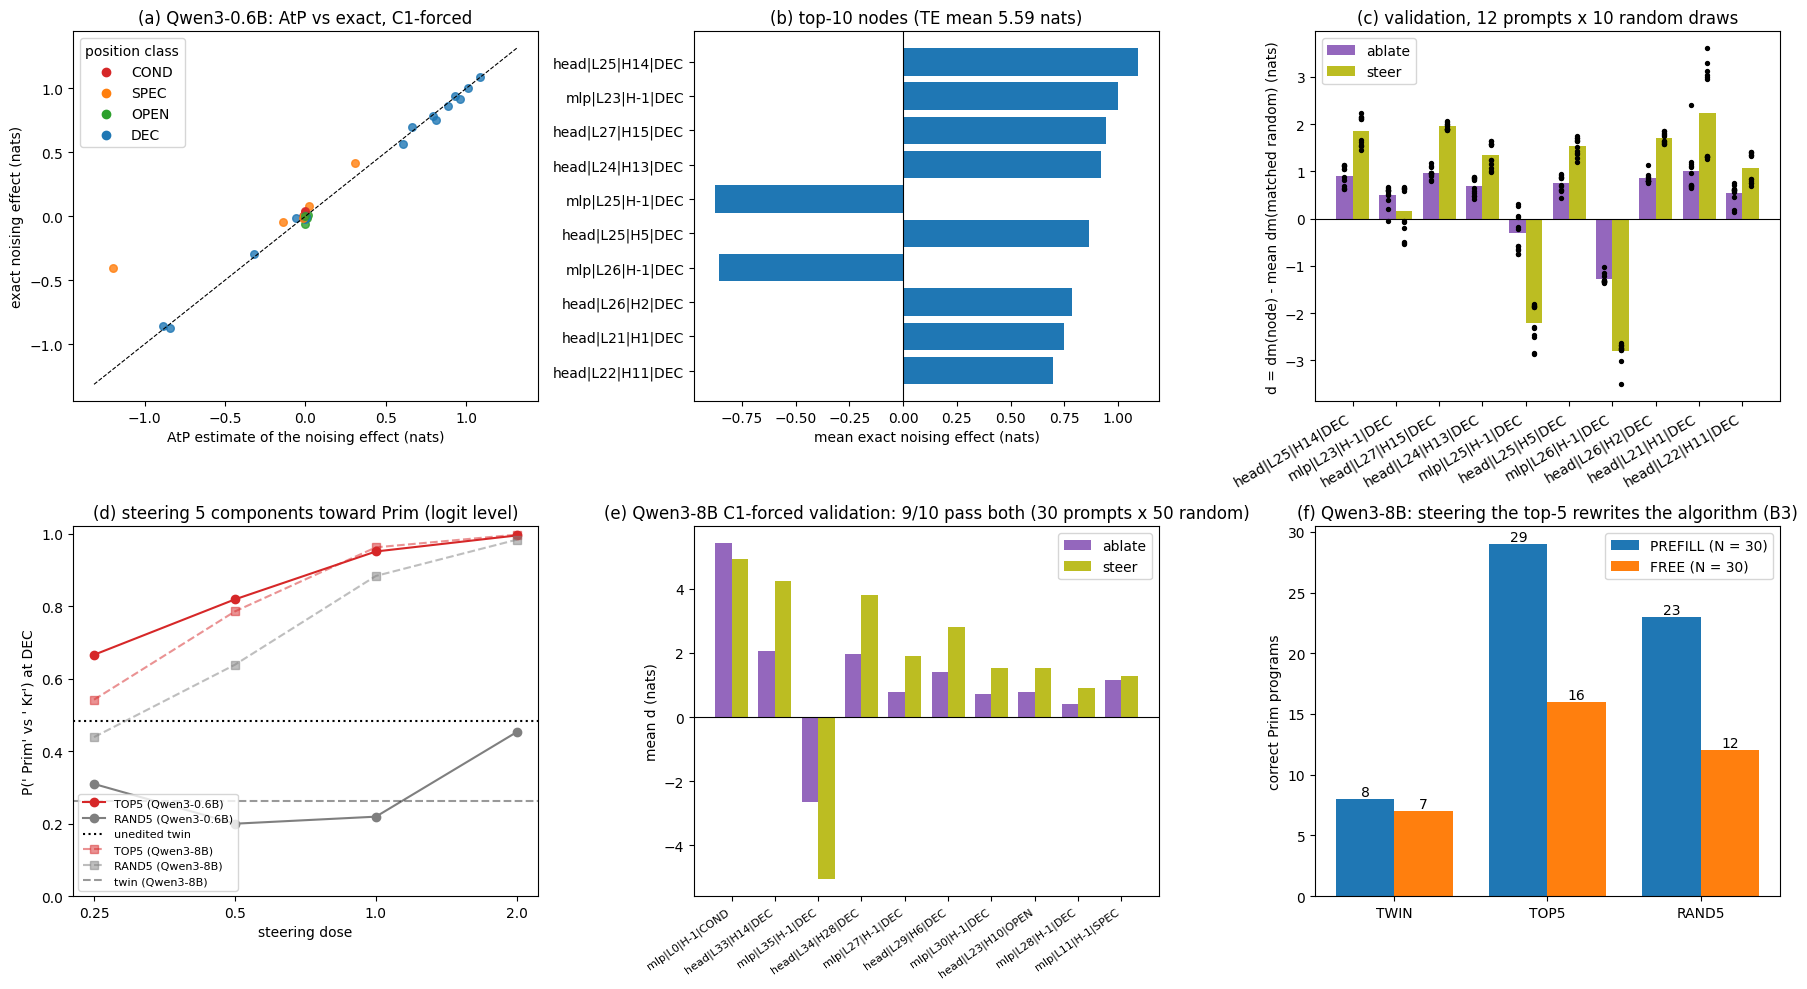

In [24]:
CLS_COLOR = {"COND": "tab:red", "SPEC": "tab:orange", "OPEN": "tab:green", "DEC": "tab:blue"}
circ = read_json(RESULTS_DIR / "circuit_C1forced.json")
rows = {r["node"]: r for r in circ.get("reliability_rows", [])}
rows.update({r["node"]: r for r in circ["exact"]})

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
# (a) AtP vs exact noising effect
ax = axes[0, 0]
for r in rows.values():
    ax.scatter(r["atp_mean"], r["noise_mean"], color=CLS_COLOR[r["node"].split("|")[3]], s=30, alpha=0.8)
lim = 1.1 * max(1e-3, max(max(abs(r["atp_mean"]), abs(r["noise_mean"])) for r in rows.values()))
ax.plot([-lim, lim], [-lim, lim], "k--", lw=0.8)
for cl, col in CLS_COLOR.items():
    ax.scatter([], [], color=col, label=cl)
ax.legend(title="position class")
ax.set(xlabel="AtP estimate of the noising effect (nats)", ylabel="exact noising effect (nats)",
       title=f"(a) {MODEL_ID.split('/')[-1]}: AtP vs exact, C1-forced")
# (b) top-10 by |exact noising effect|
ax = axes[0, 1]
top = sorted(rows.values(), key=lambda r: -abs(r["noise_mean"]))[:10][::-1]
ax.barh([r["node"] for r in top], [r["noise_mean"] for r in top],
        color=[CLS_COLOR[r["node"].split("|")[3]] for r in top])
ax.axvline(0, color="k", lw=0.8)
ax.set(xlabel="mean exact noising effect (nats)", title=f"(b) top-10 nodes (TE mean {circ['TE_mean']:.2f} nats)")
# (c) validation d per node
ax = axes[0, 2]
w = 0.38
for off, mode, col in ((-w / 2, "ablate", "tab:purple"), (w / 2, "steer", "tab:olive")):
    recs = vstats["per_node"][mode]
    ax.bar(np.arange(len(recs)) + off, [r["mean_d"] for r in recs], w, color=col, label=mode)
    for i, r in enumerate(recs):
        ax.scatter(np.full(len(r["d_per_prompt"]), i + off), r["d_per_prompt"], color="k", s=8, zorder=3)
ax.set_xticks(range(len(vstats["node_pass"])), [p["node"] for p in vstats["node_pass"]], rotation=30, ha="right")
ax.axhline(0, color="k", lw=0.8)
ax.legend()
ax.set(ylabel="d = dm(node) - mean dm(matched random) (nats)",
       title=f"(c) validation, {vstats['n_prompts']} prompts x {N_RAND} random draws")
# (d) dose response (logit level)
ax = axes[1, 0]
doses = (0.25, 0.5, 1.0, 2.0)
for arm, col in (("TOP5", "tab:red"), ("RAND5", "tab:gray")):
    ax.plot(doses, [np.mean([r["p_minority_2way"] for r in dl if r["arm"] == arm and r["dose"] == d]) for d in doses],
            "o-", color=col, label=f"{arm} ({MODEL_ID.split('/')[-1]})")
ax.axhline(twin_p, color="k", ls=":", label="unedited twin")
S = data["metadata"]["summary"]
ref = S["dose_sensitivity"]["C1forced"]
for arm, col in (("TOP5", "tab:red"), ("RAND5", "tab:gray")):
    ax.plot(doses, [ref["logit_p_minority_mean"][arm][str(d)] for d in doses], "s--", color=col, alpha=0.5,
            label=f"{arm} (Qwen3-8B)")
ax.axhline(ref["logit_twin_p_minority_mean"], color="k", ls="--", alpha=0.4, label="twin (Qwen3-8B)")
ax.set(xscale="log", xlabel="steering dose", ylabel="P(' Prim' vs ' Kr') at DEC", ylim=(0, 1.02),
       title="(d) steering 5 components toward Prim (logit level)")
ax.set_xticks(doses, [str(d) for d in doses])
ax.minorticks_off()
ax.legend(fontsize=8)
# (e) Qwen3-8B validation of the C1-forced top-10
ax = axes[1, 1]
v8 = S["validation"]["C1forced"]
for off, mode, col in ((-w / 2, "ablate", "tab:purple"), (w / 2, "steer", "tab:olive")):
    recs = v8["per_node"][mode]
    ax.bar(np.arange(len(recs)) + off, [r["mean_d"] for r in recs], w, color=col, label=mode)
ax.set_xticks(range(len(v8["node_pass"])), [p["node"] for p in v8["node_pass"]], rotation=35, ha="right", fontsize=8)
ax.axhline(0, color="k", lw=0.8)
ax.legend()
ax.set(ylabel="mean d (nats)", title=f"(e) Qwen3-8B C1-forced validation: {v8['n_pass_both_holm20']}/10 pass both "
       f"({v8['n_prompts']} prompts x 50 random)")
# (f) Qwen3-8B generation outcomes (60 B3 slots)
ax = axes[1, 2]
ex = data["datasets"][0]["examples"]
arms = ("TWIN", "TOP5", "RAND5")
for ci_, cond in enumerate(("PREFILL", "FREE")):
    sub = [e for e in ex if e["metadata_condition"] == cond]
    n_prim = [sum(e[f"predict_{a}"].split("|")[0] in ("prim_heap", "prim_array") and e[f"predict_{a}"].endswith("|pass")
                  for e in sub) for a in arms]
    bars = ax.bar(np.arange(3) + (ci_ - 0.5) * w, n_prim, w, label=f"{cond} (N = {len(sub)})")
    ax.bar_label(bars)
ax.set_xticks(range(3), arms)
ax.legend()
ax.set(ylabel="correct Prim programs", title="(f) Qwen3-8B: steering the top-5 rewrites the algorithm (B3)")
plt.tight_layout()
plt.show()

In [25]:
# ---------------------------------------------------------------- key numbers side by side
S = data["metadata"]["summary"]
c8, v8 = S["circuits"]["C1forced"], S["validation"]["C1forced"]
print(f"{'':34}{'this run (' + MODEL_ID.split('/')[-1] + ')':>26}{'original (Qwen3-8B)':>24}")
print(f"{'C1-forced pairs':34}{circ['n_pairs']:>26}{c8['n_pairs']:>24}")
print(f"{'mean total effect TE (nats)':34}{circ['TE_mean']:>26.2f}{c8['TE_mean']:>24.2f}")
print(f"{'AtP-vs-exact Spearman (random)':34}{circ['atp_vs_exact_random160']['spearman']:>26.2f}"
      f"{c8['atp_vs_exact_random160']['spearman']:>24.2f}")
print(f"{'AtP-vs-exact Spearman (top set)':34}{circ['atp_vs_exact_top']['spearman']:>26.2f}{c8['atp_vs_exact_top']['spearman']:>24.2f}")
print(f"{'nodes passing both tests':34}{str(vstats['n_pass_both_holm20']) + ' / ' + str(len(vstats['node_pass'])):>26}"
      f"{str(v8['n_pass_both_holm20']) + ' / 10':>24}")
print(f"{'top-1 node':34}{circ['top10'][0]:>26}{c8['top10'][0]:>24}")
print()
print("Qwen3-8B top-10 (C1-forced):", c8["top10"])
print("Qwen3-8B top-10 (C2a)      :", S["circuits"]["C2a"]["top10"])
for unit, k in (("C1 (C1-forced)", "C1_primary"), ("C2a", "C2a_replication")):
    K = S["K3"][k]
    print(f"K3 verdict {unit}: {K['verdict']} (one-sided McNemar: {K['verdict_if_one_sided_mcnemar']}); "
          f"{K['n_nodes_pass_both']}/10 nodes pass both; McNemar TOP5 vs RAND5 p = {K['mcnemar_top5_vs_rand5_p']:.3g}")
g = S["generation"]["C1forced"]["PREFILL"]["arms"]
print("Qwen3-8B B3 PREFILL correct Prim:", {a: f"{g[a]['correct_target']}/{g[a]['n']}" for a in ("TWIN", "TOP5", "RAND5")})

                                       this run (Qwen3-0.6B)     original (Qwen3-8B)
C1-forced pairs                                            4                      10
mean total effect TE (nats)                             5.59                    9.91
AtP-vs-exact Spearman (random)                          0.47                    0.29
AtP-vs-exact Spearman (top set)                         0.96                    0.89
nodes passing both tests                              7 / 10                  9 / 10
top-1 node                                  head|L25|H14|DEC         mlp|L0|H-1|COND

Qwen3-8B top-10 (C1-forced): ['mlp|L0|H-1|COND', 'head|L33|H14|DEC', 'mlp|L35|H-1|DEC', 'head|L34|H28|DEC', 'mlp|L27|H-1|DEC', 'head|L29|H6|DEC', 'mlp|L30|H-1|DEC', 'head|L23|H10|OPEN', 'mlp|L28|H-1|DEC', 'mlp|L11|H-1|SPEC']
Qwen3-8B top-10 (C2a)      : ['mlp|L27|H-1|DEC', 'mlp|L26|H-1|DEC', 'mlp|L32|H-1|DEC', 'mlp|L30|H-1|DEC', 'head|L23|H10|DEC', 'head|L27|H31|DEC', 'mlp|L28|H-1|DEC', 'mlp|L31|H-1|D

## Takeaways (the original Qwen3-8B run)

* **Node level (pre-registered): supported.** 9/10 (B3, C1-forced) and 8/10 (T10, C2a) of the top components beat 50
  norm-matched random components of the same type and position class, in both ablation and steering (Holm over 20
  tests). The failures are "brakes", components whose effect runs against the decision.
* **Generation (pre-registered): partially supported.** Steering the top five components at the decision position
  rewrites the written algorithm. B3 gives 29/30 correct Prim programs vs 8/30 for the unedited twin; T10 gives 29/30
  DFS vs 1/30. Pass rates are unchanged. At the committed dose 2, however, the matched random five also flips most
  programs (B3 23/30, T10 30/30). The TOP5-vs-RAND5 McNemar test therefore fails, and both K3 verdicts are
  **PARTIAL**. At dose 0.5, T10's top five give 30/30 DFS vs 6/30 for the random five.
* **Mechanism.** A layer-0 MLP at the instruction span carries most of the injected contrast; AtP missed it, and only
  the exhaustive exact sweep (F4b) found it. A late stack of decision-position MLPs and heads (layers 23–35) turns it
  into the decision logit. The two algorithm decisions share components (MLPs L26–L30, heads L23 H10 and L27 H31).

In this notebook's CPU test run (default config), Qwen3-0.6B shows the same qualitative picture:

* A forced-Prim instruction moves m by about 5–6 nats.
* AtP ranks the strong nodes well (Spearman ≈ 0.96 on the exact-patched set) but not the near-zero random ones (≈ 0.47).
* The top-10 nodes form a late stack of heads and MLPs at the decision position (layers 21–27 of 28).
* 7 of these 10 pass both validation tests; two of the three failures are "brake" MLPs (L25 and L26), as in Qwen3-8B.
* Steering the top five toward Prim moves P(' Prim' vs ' Kr') from about 0.48 to 0.99 at dose 2, while the matched
  random five do not.

The differences: the small model's decision position does not yet choose between ` Kr` and ` Prim`, and the demo uses
4 instead of 10 pairs and 10 instead of 50 random draws. Exact numbers vary slightly with hardware (bf16 kernels).